# MO-IT128 - Data Mining Principles - MILESTONE 1
## S3107 | Team Nexus

**Authors/Analysts:**
- Abegail Imee Enriquez - Lead Developer & Data Analyst  
- Francisco Cabangon - MS 1 Team Leader & Data Analyst  
- Alvin Tubtub - Quality Assurance Analyst  
- Jeffrey Dollopac - Asst. Quality Assurance Analyst  


# FinMark Corporation
## Project Data Preparation, Feature Engineering, and Exploratory Data Analysis

This notebook consolidates the full Milestone 1 workflow in a single file:

1. Load raw datasets  
2. Apply minimal pre-merge harmonization (only what is required to join consistently)  
3. Create a **customer-level feedback summary** to define a stable merge grain  
4. Merge transactions and customer data **before** full cleaning  
5. Clean and standardize the merged dataset  
6. Clean the product offering dataset as a separate, submission-ready output  
7. Perform feature engineering (including **income grouping** using quartiles/percentiles derived from transaction amounts)  
8. Conduct EDA and visualizations to understand the merged dataset and engineered outputs  
9. Export cleaned and engineered datasets

In [1]:

# ---------------------------
# Project Paths & Folder Setup
# ---------------------------
# Expected folder structure (within Milestone 1 root):
# Data/Raw, Data/Cleaned, Features, Notebook, Documentation

from pathlib import Path
import pandas as pd
import numpy as np

def resolve_project_root() -> Path:
    cwd = Path.cwd().resolve()
    # If running inside "Notebook" folder, use parent as root when "Data" exists
    if cwd.name.lower() == "notebook" and (cwd.parent / "Data").exists():
        return cwd.parent
    # If running at root already
    if (cwd / "Data").exists():
        return cwd
    # Fallback: try parent
    if (cwd.parent / "Data").exists():
        return cwd.parent
    return cwd

PROJECT_ROOT = resolve_project_root()

DATA_DIR = PROJECT_ROOT / "Data"
RAW_DIR = DATA_DIR / "Raw"
CLEANED_DIR = DATA_DIR / "Cleaned"
FEATURES_DIR = PROJECT_ROOT / "Features"
NOTEBOOK_DIR = PROJECT_ROOT / "Notebook"
DOCS_DIR = PROJECT_ROOT / "Documentation"

for p in [RAW_DIR, CLEANED_DIR, FEATURES_DIR, NOTEBOOK_DIR, DOCS_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data dir:", RAW_DIR)
print("Cleaned dir:", CLEANED_DIR)
print("Features dir:", FEATURES_DIR)


Project root: /Users/arenriquez1/DataAnalyticsProjects/MO-IT128-DMP_S3101_Nexus/Milestone 1
Raw data dir: /Users/arenriquez1/DataAnalyticsProjects/MO-IT128-DMP_S3101_Nexus/Milestone 1/Data/Raw
Cleaned dir: /Users/arenriquez1/DataAnalyticsProjects/MO-IT128-DMP_S3101_Nexus/Milestone 1/Data/Cleaned
Features dir: /Users/arenriquez1/DataAnalyticsProjects/MO-IT128-DMP_S3101_Nexus/Milestone 1/Features


## 0) Setup

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 250)
pd.set_option("display.width", 140)
pd.options.display.float_format = "{:,.2f}".format


## 1) Load raw datasets

**Datasets**
- **Transactions:** customer activity records (dates, types, amounts)
- **Customer Feedback:** satisfaction and recommendation signals (multiple rows may exist per customer)
- **Product Offering:** product catalog/context (no reliable join key provided for transaction linkage)

The merge-first workflow depends on consistently formatted join keys and correct parsing of timestamp fields.


In [3]:

# ---------------------------
# Load Raw Data (from Data/Raw)
# ---------------------------
# Files expected in Data/Raw:
# - Transaction_Data.csv
# - Customer_Feedback_Data.csv
# - Product_Offering_Data.csv

transactions_raw = pd.read_csv(RAW_DIR / "Transaction_Data.csv")
feedback_raw = pd.read_csv(RAW_DIR / "Customer_Feedback_Data.csv")
products_raw = pd.read_csv(RAW_DIR / "Product_Offering_Data.csv")

print("Transactions:", transactions_raw.shape)
print("Feedback:", feedback_raw.shape)
print("Products:", products_raw.shape)

display(transactions_raw.head())
display(feedback_raw.head())
display(products_raw.head())


Transactions: (5050, 5)
Feedback: (5050, 4)
Products: (15, 6)


,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Amount,Transaction_Type
0,1,393,2023-01-01 00:00:00,"3,472.00",Purchase
1,2,826,2023-01-01 01:00:00,NaN,Bill Payment
2,3,916,2023-01-01 02:00:00,10.00,Purchase
3,4,109,2023-01-01 03:00:00,72.00,Investment
4,5,889,2023-01-01 04:00:00,"1,793.00",Investment


,Customer_ID,Satisfaction_Score,Feedback_Comments,Likelihood_to_Recommend
0,1,10.00,Very satisfied,9
1,2,3.00,Very satisfied,3
2,3,10.00,Very satisfied,1
3,4,7.00,Needs improvement,4
4,5,8.00,Unsatisfactory,7


,Product_ID,Product_Name,Product_Type,Risk_Level,Target_Age_Group,Target_Income_Group
0,1,Platinum Credit Card,Credit Card,Medium,NaN,Medium
1,2,Gold Savings Account,Savings Account,Low,NaN,Low
2,3,High-Yield Investment Account,Investment,High,NaN,High
3,4,Mortgage Loan,Loan,Medium,NaN,High
4,5,Auto Loan,Loan,Medium,NaN,Medium


## 2) Pre-merge harmonization (minimal)

Only minimal transformations are performed at this stage to avoid repeated processing:
- `Customer_ID` is standardized as trimmed text
- `Transaction_Date` is parsed to datetime (errors coerced to missing)
- Feedback numeric fields are coerced to numeric types for reliable aggregation


In [4]:
def norm_id(s):
    if pd.isna(s):
        return s
    return str(s).strip()

for df in (transactions_raw, feedback_raw, products_raw):
    if "Customer_ID" in df.columns:
        df["Customer_ID"] = df["Customer_ID"].apply(norm_id)

if "Transaction_Date" in transactions_raw.columns:
    transactions_raw["Transaction_Date"] = pd.to_datetime(transactions_raw["Transaction_Date"], errors="coerce")

for c in ["Satisfaction_Score", "Likelihood_to_Recommend"]:
    if c in feedback_raw.columns:
        feedback_raw[c] = pd.to_numeric(feedback_raw[c], errors="coerce")

if "Feedback_Comments" in feedback_raw.columns:
    feedback_raw["Feedback_Comments"] = feedback_raw["Feedback_Comments"].astype(str).replace("nan", np.nan).str.strip()

display(transactions_raw.head())


,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Amount,Transaction_Type
0,1,393,2023-01-01 00:00:00,"3,472.00",Purchase
1,2,826,2023-01-01 01:00:00,NaN,Bill Payment
2,3,916,2023-01-01 02:00:00,10.00,Purchase
3,4,109,2023-01-01 03:00:00,72.00,Investment
4,5,889,2023-01-01 04:00:00,"1,793.00",Investment


## 3) Define customer-level feedback summary (stable merge grain)

Feedback data can contain multiple entries per customer. A direct merge between transactions and raw feedback rows can inflate row counts and distort downstream calculations.

To maintain a stable, model-friendly grain, feedback is summarized to **one row per customer**:
- count of feedback entries  
- mean and standard deviation for satisfaction and likelihood-to-recommend  
- most frequent feedback comment label (mode) when available  


In [5]:

# -----------------------------------------
# Customer Feedback Summary (Cap + Winsorize)
# -----------------------------------------
# Notes:
# - Satisfaction_Score and Likelihood_to_Recommend are treated as 1–10 scales.
# - Scores are capped to 1–10, then winsorized (percentile clipping) to reduce the influence of extreme values.
# - Feedback_Comment is dropped from the engineered dataset to reduce redundancy and keep the workflow lean.

fb = feedback_raw.copy()

# Standardize column names if needed (safe-guards)
# Expected: Customer_ID, Satisfaction_Score, Likelihood_to_Recommend, Feedback_Comment
for col in ["Satisfaction_Score", "Likelihood_to_Recommend"]:
    if col in fb.columns:
        fb[col] = pd.to_numeric(fb[col], errors="coerce")

# Cap scores to expected ranges
if "Satisfaction_Score" in fb.columns:
    fb["Satisfaction_Score"] = fb["Satisfaction_Score"].clip(lower=1, upper=10)
if "Likelihood_to_Recommend" in fb.columns:
    fb["Likelihood_to_Recommend"] = fb["Likelihood_to_Recommend"].clip(lower=1, upper=10)

def winsorize_series(s: pd.Series, lower_q=0.05, upper_q=0.95) -> pd.Series:
    s = s.astype(float)
    lo = s.quantile(lower_q)
    hi = s.quantile(upper_q)
    return s.clip(lower=lo, upper=hi)

# Winsorized versions (for analysis + aggregation)
if "Satisfaction_Score" in fb.columns:
    fb["Satisfaction_W"] = winsorize_series(fb["Satisfaction_Score"])
if "Likelihood_to_Recommend" in fb.columns:
    fb["LTR_W"] = winsorize_series(fb["Likelihood_to_Recommend"])

# Drop comment column from downstream engineered data (still available in the raw file)
if "Feedback_Comment" in fb.columns:
    fb = fb.drop(columns=["Feedback_Comment"])

feedback_customer_summary = (
    fb.groupby("Customer_ID", dropna=False)
      .agg(
          feedback_count=("Customer_ID", "size"),

          satisfaction_mean=("Satisfaction_W", "mean"),
          satisfaction_std=("Satisfaction_W", "std"),
          satisfaction_min=("Satisfaction_W", "min"),
          satisfaction_max=("Satisfaction_W", "max"),

          ltr_mean=("LTR_W", "mean"),
          ltr_std=("LTR_W", "std"),
          ltr_min=("LTR_W", "min"),
          ltr_max=("LTR_W", "max"),
      )
      .reset_index()
)

# Fill NaNs from std (customers with single feedback entry)
for c in ["satisfaction_std", "ltr_std"]:
    if c in feedback_customer_summary.columns:
        feedback_customer_summary[c] = feedback_customer_summary[c].fillna(0)

display(feedback_customer_summary.head())
print("Feedback customer summary:", feedback_customer_summary.shape)


,Customer_ID,feedback_count,satisfaction_mean,satisfaction_std,satisfaction_min,satisfaction_max,ltr_mean,ltr_std,ltr_min,ltr_max
0,1,2,8.50,2.12,7.00,10.00,9.00,0.00,9.00,9.00
1,10,5,5.40,2.19,3.00,7.00,3.00,2.12,1.00,6.00
2,100,2,8.00,1.41,7.00,9.00,7.50,3.54,5.00,10.00
3,1000,4,4.25,1.71,2.00,6.00,8.00,2.16,5.00,10.00
4,101,7,5.00,3.92,1.00,10.00,7.14,3.29,1.00,10.00


Feedback customer summary: (1000, 10)


## 4) Merge first (transactions + customer summary)

The merged dataset becomes the single source of truth for cleaning, feature engineering, and EDA.


In [6]:
merged_raw = transactions_raw.merge(feedback_customer_summary, on="Customer_ID", how="left")
print("Merged (raw) shape:", merged_raw.shape)
display(merged_raw.head())


Merged (raw) shape: (5050, 14)


,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Amount,Transaction_Type,feedback_count,satisfaction_mean,satisfaction_std,satisfaction_min,satisfaction_max,ltr_mean,ltr_std,ltr_min,ltr_max
0,1,393,2023-01-01 00:00:00,"3,472.00",Purchase,1,1.00,0.00,1.00,1.00,3.00,0.00,3.00,3.00
1,2,826,2023-01-01 01:00:00,NaN,Bill Payment,6,6.20,3.27,3.00,10.00,5.50,2.88,3.00,10.00
2,3,916,2023-01-01 02:00:00,10.00,Purchase,7,2.71,2.06,1.00,6.00,5.00,3.21,1.00,10.00
3,4,109,2023-01-01 03:00:00,72.00,Investment,3,3.00,1.00,2.00,4.00,7.00,2.00,5.00,9.00
4,5,889,2023-01-01 04:00:00,"1,793.00",Investment,5,5.00,3.08,1.00,8.00,5.60,2.70,3.00,9.00


## 5) Data quality assessment (merged)

This step documents baseline data quality:
- missing values overview  
- duplicates (using transaction identifiers when available)  


In [7]:
merged = merged_raw.copy()

display(merged.isna().sum().sort_values(ascending=False).head(15))

txn_key_cols = [c for c in ["Transaction_ID","Customer_ID","Transaction_Date","Transaction_Type","Transaction_Amount"] if c in merged.columns]
print("Duplicate-check keys:", txn_key_cols)

dup_count = merged.duplicated(subset=txn_key_cols).sum() if txn_key_cols else merged.duplicated().sum()
print("Duplicates detected:", int(dup_count))


Transaction_Amount    100
Transaction_ID          0
Customer_ID             0
Transaction_Date        0
Transaction_Type        0
feedback_count          0
satisfaction_mean       0
satisfaction_std        0
satisfaction_min        0
satisfaction_max        0
ltr_mean                0
ltr_std                 0
ltr_min                 0
ltr_max                 0
dtype: int64

Duplicate-check keys: ['Transaction_ID', 'Customer_ID', 'Transaction_Date', 'Transaction_Type', 'Transaction_Amount']
Duplicates detected: 50


## 6) Cleaning and standardization (merged)

**Decisions applied**
- **Duplicates:** removed using transaction-level key fields (when available).
- **Missing transaction amounts:** imputed using median-per-transaction-type (fallback to global median).
- **Category labels:** `Transaction_Type` trimmed and standardized; missing values set to `Unknown`.
- **Outliers:** IQR-based capping applied to reduce distortion while retaining records.
- **Presentation:** numeric fields rounded to 2 decimals for clean exported outputs.


In [8]:
# 6.1 Remove duplicates
if txn_key_cols:
    merged = merged.drop_duplicates(subset=txn_key_cols, keep="first")
else:
    merged = merged.drop_duplicates(keep="first")

# 6.2 Transaction amount cleanup + missing handling
if "Transaction_Amount" in merged.columns:
    merged["Transaction_Amount"] = pd.to_numeric(merged["Transaction_Amount"], errors="coerce")
    merged["amount_was_missing"] = merged["Transaction_Amount"].isna().astype(int)

    if "Transaction_Type" in merged.columns:
        med_by_type = merged.groupby("Transaction_Type")["Transaction_Amount"].transform("median")
        merged["Transaction_Amount"] = merged["Transaction_Amount"].fillna(med_by_type).fillna(merged["Transaction_Amount"].median())
    else:
        merged["Transaction_Amount"] = merged["Transaction_Amount"].fillna(merged["Transaction_Amount"].median())

# 6.3 Normalize Transaction_Type formatting
if "Transaction_Type" in merged.columns:
    merged["Transaction_Type"] = merged["Transaction_Type"].astype(str).str.strip()
    merged.loc[merged["Transaction_Type"].str.lower().isin(["nan","none",""]),"Transaction_Type"] = np.nan
    merged["Transaction_Type"] = merged["Transaction_Type"].fillna("Unknown")

# 6.4 Outlier handling (IQR cap)
if "Transaction_Amount" in merged.columns:
    q1 = merged["Transaction_Amount"].quantile(0.25)
    q3 = merged["Transaction_Amount"].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5*iqr
    upper = q3 + 1.5*iqr

    merged["amount_outlier_flag"] = ((merged["Transaction_Amount"] < lower) | (merged["Transaction_Amount"] > upper)).astype(int)
    merged["Transaction_Amount"] = merged["Transaction_Amount"].clip(lower=lower, upper=upper)

# 6.5 Clean-looking numeric output
num_cols = merged.select_dtypes(include=[np.number]).columns
merged[num_cols] = merged[num_cols].round(2)

# 6.6 Date parts for EDA context
if "Transaction_Date" in merged.columns:
    merged["Transaction_Year"] = merged["Transaction_Date"].dt.year.astype("Int64")
    merged["Transaction_Month"] = merged["Transaction_Date"].dt.month.astype("Int64")

print("Merged (cleaned) shape:", merged.shape)
display(merged.head())


Merged (cleaned) shape: (5000, 18)


,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Amount,Transaction_Type,feedback_count,satisfaction_mean,satisfaction_std,satisfaction_min,satisfaction_max,ltr_mean,ltr_std,ltr_min,ltr_max,amount_was_missing,amount_outlier_flag,Transaction_Year,Transaction_Month
0,1,393,2023-01-01 00:00:00,"3,472.00",Purchase,1,1.00,0.00,1.00,1.00,3.00,0.00,3.00,3.00,0,0,2023,1
1,2,826,2023-01-01 01:00:00,"2,485.00",Bill Payment,6,6.20,3.27,3.00,10.00,5.50,2.88,3.00,10.00,1,0,2023,1
2,3,916,2023-01-01 02:00:00,10.00,Purchase,7,2.71,2.06,1.00,6.00,5.00,3.21,1.00,10.00,0,0,2023,1
3,4,109,2023-01-01 03:00:00,72.00,Investment,3,3.00,1.00,2.00,4.00,7.00,2.00,5.00,9.00,0,0,2023,1
4,5,889,2023-01-01 04:00:00,"1,793.00",Investment,5,5.00,3.08,1.00,8.00,5.60,2.70,3.00,9.00,0,0,2023,1


## 7) Product offering cleanup (separate output)

The product dataset is cleaned as a separate output because the provided tables do not include a reliable key for transaction-level joins.


In [9]:
import re

products = products_raw.copy()

for c in products.columns:
    if products[c].dtype == "object":
        products[c] = products[c].astype(str).replace("nan", np.nan).str.strip()

for c in products.columns:
    if re.search(r"(price|cost|amount|revenue|margin)", c, re.IGNORECASE):
        products[c] = pd.to_numeric(products[c], errors="coerce")

products = products.drop_duplicates()

pnum = products.select_dtypes(include=[np.number]).columns
products[pnum] = products[pnum].round(2)

print("Products (cleaned) shape:", products.shape)
display(products.head())


Products (cleaned) shape: (10, 6)


,Product_ID,Product_Name,Product_Type,Risk_Level,Target_Age_Group,Target_Income_Group
0,1,Platinum Credit Card,Credit Card,Medium,NaN,Medium
1,2,Gold Savings Account,Savings Account,Low,NaN,Low
2,3,High-Yield Investment Account,Investment,High,NaN,High
3,4,Mortgage Loan,Loan,Medium,NaN,High
4,5,Auto Loan,Loan,Medium,NaN,Medium


## 8) Feature engineering (post-clean)

This section creates new variables that are useful for later modeling and for interpretability during EDA.

**Included feature groups**
- **Temporal features** from `Transaction_Date` (week/year, time-of-day)
- **Spend trends** (daily and weekly totals grouped correctly)
- **Feedback sentiment encoding** using the most common feedback category
- **Income grouping** derived from transaction-derived spend metrics using quartiles (Low / Medium / High)


In [10]:
df = merged.copy()

# 8.1 Temporal feature extraction
if "Transaction_Date" in df.columns:
    df["Transaction_Day"] = df["Transaction_Date"].dt.date
    df["Transaction_Week"] = df["Transaction_Date"].dt.isocalendar().week.astype("Int64")
    df["Transaction_ISOYear"] = df["Transaction_Date"].dt.isocalendar().year.astype("Int64")
    df["Transaction_DayOfWeek"] = df["Transaction_Date"].dt.day_name()
    df["Transaction_Hour"] = df["Transaction_Date"].dt.hour.astype("Int64")

    def time_of_day_bucket(h):
        if pd.isna(h): return "Unknown"
        h=int(h)
        if 5 <= h <= 11: return "Morning"
        if 12 <= h <= 16: return "Afternoon"
        if 17 <= h <= 20: return "Evening"
        return "Night"

    df["Transaction_TimeOfDay"] = df["Transaction_Hour"].apply(time_of_day_bucket)

# 8.2 Feedback sentiment encoding (from top_comment)
sentiment_map = {
    "Excellent": 1.0,
    "Very Satisfied": 1.0,
    "Good Service": 0.5,
    "Needs Improvement": -0.5,
    "Unsatisfactory": -1.0,
}
df["top_comment_sentiment"] = df.get("top_comment", pd.Series([np.nan]*len(df))).map(sentiment_map).fillna(0.0)

# 8.3 Customer-level spend proxy (transaction-derived)
customer_spend = df.groupby("Customer_ID", as_index=False).agg(
    total_spend=("Transaction_Amount", "sum"),
    avg_spend=("Transaction_Amount", "mean"),
    txn_count=("Transaction_ID", "size") if "Transaction_ID" in df.columns else ("Transaction_Amount", "size"),
)

p_low = 0.20  # 20th percentile
p_high = 0.75 # 75th percentile
p_low_spend = customer_spend["total_spend"].quantile(p_low)
p_high_spend = customer_spend["total_spend"].quantile(p_high)
def income_group(x):
    if pd.isna(x): return "Medium"
    if x <= p_low_spend: return "Low"
    if x >= p_high_spend: return "High"
    return "Medium"

customer_spend["Income_Group"] = customer_spend["total_spend"].apply(income_group)

# Attach Income_Group back to transactions
df = df.merge(customer_spend[["Customer_ID","Income_Group"]], on="Customer_ID", how="left")

# 8.4 Daily/Weekly spend trends (grouped correctly)
daily = df.groupby(["Customer_ID","Transaction_Day"], as_index=False).agg(Daily_Spend_Trend=("Transaction_Amount","sum"))
df = df.merge(daily, on=["Customer_ID","Transaction_Day"], how="left")

weekly = df.groupby(["Customer_ID","Transaction_ISOYear","Transaction_Week"], as_index=False).agg(Weekly_Spend_Trend=("Transaction_Amount","sum"))
df = df.merge(weekly, on=["Customer_ID","Transaction_ISOYear","Transaction_Week"], how="left")

# Presentation cleanup
num_cols = df.select_dtypes(include=[np.number]).columns
df[num_cols] = df[num_cols].round(2)

display(df.head())
print("Income group cutoffs (total_spend, percentile-based tiers):")
print("P33 (33%):", round(p_low_spend,2), "| P67 (67%):", round(p_high_spend,2))


,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Amount,Transaction_Type,feedback_count,satisfaction_mean,satisfaction_std,satisfaction_min,satisfaction_max,ltr_mean,ltr_std,ltr_min,ltr_max,amount_was_missing,amount_outlier_flag,Transaction_Year,Transaction_Month,Transaction_Day,Transaction_Week,Transaction_ISOYear,Transaction_DayOfWeek,Transaction_Hour,Transaction_TimeOfDay,top_comment_sentiment,Income_Group,Daily_Spend_Trend,Weekly_Spend_Trend
0,1,393,2023-01-01 00:00:00,"3,472.00",Purchase,1,1.00,0.00,1.00,1.00,3.00,0.00,3.00,3.00,0,0,2023,1,2023-01-01,52,2022,Sunday,0,Night,0.00,High,"3,472.00","3,472.00"
1,2,826,2023-01-01 01:00:00,"2,485.00",Bill Payment,6,6.20,3.27,3.00,10.00,5.50,2.88,3.00,10.00,1,0,2023,1,2023-01-01,52,2022,Sunday,1,Night,0.00,Medium,"2,485.00","2,485.00"
2,3,916,2023-01-01 02:00:00,10.00,Purchase,7,2.71,2.06,1.00,6.00,5.00,3.21,1.00,10.00,0,0,2023,1,2023-01-01,52,2022,Sunday,2,Night,0.00,High,"1,062.00","1,062.00"
3,4,109,2023-01-01 03:00:00,72.00,Investment,3,3.00,1.00,2.00,4.00,7.00,2.00,5.00,9.00,0,0,2023,1,2023-01-01,52,2022,Sunday,3,Night,0.00,Medium,72.00,72.00
4,5,889,2023-01-01 04:00:00,"1,793.00",Investment,5,5.00,3.08,1.00,8.00,5.60,2.70,3.00,9.00,0,0,2023,1,2023-01-01,52,2022,Sunday,4,Night,0.00,Low,"1,793.00","1,793.00"


Income group cutoffs (total_spend, percentile-based tiers):
P33 (33%): 6860.2 | P67 (67%): 16531.0


## 9) Customer-level feature table (segmentation-ready)

This table aggregates transaction-level behavior into one row per customer.  
It includes spend intensity, timing patterns, transaction type mix, and feedback summary signals.


In [11]:
from sklearn.preprocessing import StandardScaler

# Recency/tenure
overall_last = df["Transaction_Date"].max()
tenure = df.groupby("Customer_ID").agg(
    first_txn=("Transaction_Date", "min"),
    last_txn=("Transaction_Date", "max"),
    active_days=("Transaction_Day", "nunique"),
).reset_index()
tenure["tenure_days"] = (tenure["last_txn"] - tenure["first_txn"]).dt.days.clip(lower=0)
tenure["recency_days"] = (overall_last - tenure["last_txn"]).dt.days.clip(lower=0)

# Timing ratios
tmp = df.copy()
tmp["dow"] = tmp["Transaction_Date"].dt.dayofweek
tmp["is_weekend"] = tmp["dow"].isin([5,6]).astype(int)
tmp["is_business_hours"] = tmp["Transaction_Hour"].between(9,16).astype(int)

timing = tmp.groupby("Customer_ID").agg(
    pct_weekend_txn=("is_weekend","mean"),
    pct_business_hours_txn=("is_business_hours","mean"),
    avg_txn_hour=("Transaction_Hour","mean"),
).reset_index()

# Transaction type distribution
type_dist = df.pivot_table(index="Customer_ID", columns="Transaction_Type", values="Transaction_Amount", aggfunc="size", fill_value=0).reset_index()
type_cols = [c for c in type_dist.columns if c!="Customer_ID"]
type_dist = type_dist.rename(columns={c: f"count_type_{str(c).lower().replace(' ','_')}" for c in type_cols})

# Time-of-day proportions
tod = pd.get_dummies(df[["Customer_ID","Transaction_TimeOfDay"]], columns=["Transaction_TimeOfDay"])
tod = tod.groupby("Customer_ID").mean().reset_index()
tod = tod.rename(columns={c: c.replace("Transaction_TimeOfDay_", "pct_tod_") for c in tod.columns if c.startswith("Transaction_TimeOfDay_")})

# Risk proxy on transaction amount
q25 = df["Transaction_Amount"].quantile(0.25)
q75 = df["Transaction_Amount"].quantile(0.75)
df["risk_proxy"] = np.where(df["Transaction_Amount"]>=q75, "High", np.where(df["Transaction_Amount"]<=q25, "Low", "Medium"))
risk = df.groupby("Customer_ID").agg(
    high_risk_txn_count=("risk_proxy", lambda s: int((s=="High").sum())),
    pct_high_risk_txn=("risk_proxy", lambda s: float((s=="High").mean())),
).reset_index()

# Assemble customer features
customer_features = (
    customer_spend.merge(tenure[["Customer_ID","active_days","tenure_days","recency_days"]], on="Customer_ID", how="left")
                 .merge(timing, on="Customer_ID", how="left")
                 .merge(type_dist, on="Customer_ID", how="left")
                 .merge(tod, on="Customer_ID", how="left")
                 .merge(risk, on="Customer_ID", how="left")
                 .merge(feedback_customer_summary, on="Customer_ID", how="left")
)

# Fill missing values
for col in customer_features.columns:
    if col == "Customer_ID":
        continue
    if customer_features[col].dtype.kind in "biufc":
        customer_features[col] = customer_features[col].fillna(0)
    else:
        customer_features[col] = customer_features[col].fillna("Unknown")

customer_features = customer_features.round(2)
display(customer_features.head())


# -------------------------------------------------------
# Income Group (Quartile-based on transaction-derived spend)
# -------------------------------------------------------
# A practical income proxy is derived from customer-level total spend:
# - Low: <= Q1
# - Medium: Q1 to Q3
# - High: > Q3

q1 = customer_features["total_spend"].quantile(0.25)
q3 = customer_features["total_spend"].quantile(0.75)

def assign_income_group(x: float, q1: float, q3: float) -> str:
    if x <= q1:
        return "Low"
    if x <= q3:
        return "Medium"
    return "High"

customer_features["Income_Group"] = customer_features["total_spend"].apply(lambda x: assign_income_group(x, q1, q3))

# -----------------------------------------
# Sentiment proxy (score-derived, 1–5 scale)
# -----------------------------------------
# Feedback comments are intentionally excluded from features to reduce redundancy.
# A simple sentiment proxy is derived from mean satisfaction:
#   1 = Negative (<=4), 3 = Neutral (5–7), 5 = Positive (>=8)
if "satisfaction_mean" in customer_features.columns:
    customer_features["feedback_sentiment_mean"] = pd.cut(
        customer_features["satisfaction_mean"],
        bins=[-np.inf, 4, 7, np.inf],
        labels=[1, 3, 5]
    ).astype(int)
else:
    customer_features["feedback_sentiment_mean"] = 3
# Scaled version for clustering
numeric_cols = [c for c in customer_features.columns if c not in ["Customer_ID","Income_Group",] and customer_features[c].dtype.kind in "biufc"]
scaler = StandardScaler()
scaled = scaler.fit_transform(customer_features[numeric_cols]) if numeric_cols else np.empty((len(customer_features),0))
customer_features_scaled = pd.DataFrame(scaled, columns=numeric_cols)
customer_features_scaled.insert(0, "Customer_ID", customer_features["Customer_ID"].values)

print("Customer features shape:", customer_features.shape)


,Customer_ID,total_spend,avg_spend,txn_count,Income_Group,active_days,tenure_days,recency_days,pct_weekend_txn,pct_business_hours_txn,avg_txn_hour,count_type_bill_payment,count_type_investment,count_type_loan_payment,count_type_purchase,pct_tod_Afternoon,pct_tod_Evening,pct_tod_Morning,pct_tod_Night,high_risk_txn_count,pct_high_risk_txn,feedback_count,satisfaction_mean,satisfaction_std,satisfaction_min,satisfaction_max,ltr_mean,ltr_std,ltr_min,ltr_max
0,1,"16,836.00","2,806.00",6,High,6,180,26,0.17,0.17,6.83,3,1,1,1,0.17,0.17,0.00,0.67,3,0.50,2,8.50,2.12,7.00,10.00,9.00,0.00,9.00,9.00
1,10,"15,682.00","2,613.67",6,Medium,6,126,5,0.50,0.67,13.50,3,1,0,2,0.50,0.17,0.33,0.00,2,0.33,5,5.40,2.19,3.00,7.00,3.00,2.12,1.00,6.00
2,100,"5,850.00","1,462.50",4,Low,4,106,8,0.00,0.25,9.50,1,1,1,1,0.25,0.00,0.00,0.75,0,0.00,2,8.00,1.41,7.00,9.00,7.50,3.54,5.00,10.00
3,1000,"9,652.00","1,608.67",6,Medium,6,120,37,0.17,0.17,12.50,0,2,3,1,0.00,0.50,0.50,0.00,0,0.00,4,4.25,1.71,2.00,6.00,8.00,2.16,5.00,10.00
4,101,"1,552.00","1,552.00",1,Low,1,0,139,1.00,0.00,6.00,0,1,0,0,0.00,0.00,1.00,0.00,0,0.00,7,5.00,3.92,1.00,10.00,7.14,3.29,1.00,10.00


Customer features shape: (993, 31)


## 10) EDA and visualizations

The following visual checks are included:
- Transaction amount distribution
- Transaction type mix
- Income group distribution (customer-level)
- Satisfaction vs income group (customer-level)
- Correlation scan for numeric features


### 10.1 Income Tier Segmentation (Quartile-Based) — Visual Suite
This section segments customers into **Low / Medium / High** tiers using **quartiles (Q1 & Q3) of total spending** and validates the separation through multiple views (distribution, mean spend, and spread).


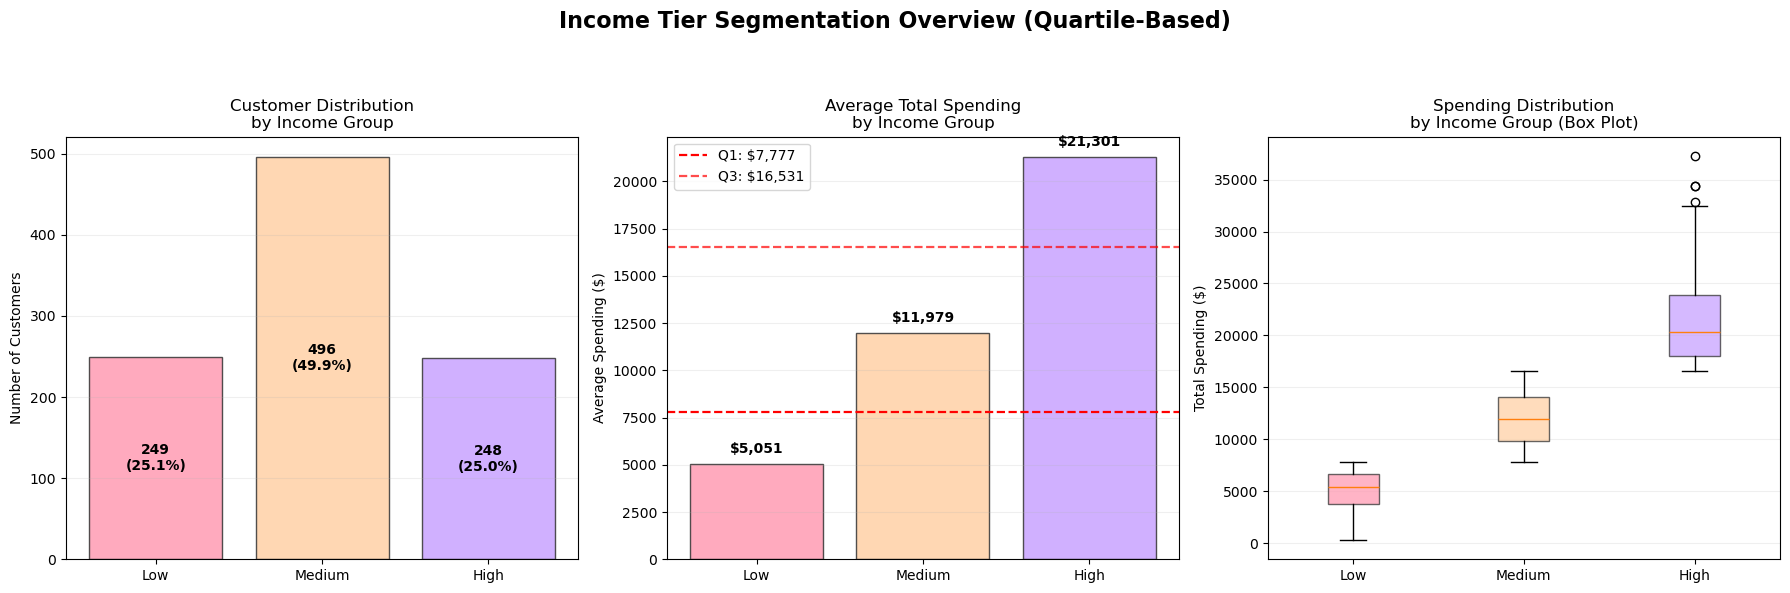


Quartile cutoffs (from total spend):
- Q1 (25%): 7,777
- Q3 (75%): 16,531


In [12]:
# =========================================================
# 10.1: INCOME GROUP ANALYSIS (Quartile-Based Segmentation)
# =========================================================
import numpy as np
import matplotlib.pyplot as plt

cf = customer_features.copy()

def pick_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

col_total = pick_col(cf, ["total_spend","Total_Spending"])
col_group = pick_col(cf, ["Income_Group","Primary_Income_Group","income_group","IncomeLevel"])

if not col_total:
    print("⚠️ Missing total spend column for income segmentation visuals.")
else:
    if not col_group:
        # Create quartile-based groups from total_spend (Q1/Q3)
        q1 = cf[col_total].quantile(0.25)
        q3 = cf[col_total].quantile(0.75)
        cf["Income_Group"] = pd.cut(
            cf[col_total],
            bins=[-np.inf, q1, q3, np.inf],
            labels=["Low", "Medium", "High"]
        )
        col_group = "Income_Group"
    else:
        q1 = cf.loc[cf[col_total].notna(), col_total].quantile(0.25)
        q3 = cf.loc[cf[col_total].notna(), col_total].quantile(0.75)

    # Pastel palette (Pink / Orange / Purple)
    palette = {"Low": "#ff9bb3", "Medium": "#ffd1a6", "High": "#c8a2ff"}

    order = ["Low", "Medium", "High"]
    grp_counts = cf[col_group].value_counts().reindex(order)
    grp_pct = (grp_counts / grp_counts.sum()) * 100
    grp_means = cf.groupby(col_group)[col_total].mean().reindex(order)

    fig = plt.figure(figsize=(18, 6))
    fig.suptitle("Income Tier Segmentation Overview (Quartile-Based)", fontsize=16, fontweight="bold")

    # (1) Distribution
    ax1 = plt.subplot(1, 3, 1)
    bars = ax1.bar(order, grp_counts.values, color=[palette[o] for o in order], edgecolor="#333", alpha=0.85)
    ax1.set_title("Customer Distribution\nby Income Group")
    ax1.set_ylabel("Number of Customers")
    ax1.grid(axis="y", alpha=0.2)
    for b, o in zip(bars, order):
        ax1.text(b.get_x()+b.get_width()/2, b.get_height()*0.5,
                 f"{int(grp_counts[o])}\n({grp_pct[o]:.1f}%)",
                 ha="center", va="center", fontweight="bold")

    # (2) Avg spend by group (with Q1/Q3 lines)
    ax2 = plt.subplot(1, 3, 2)
    bars2 = ax2.bar(order, grp_means.values, color=[palette[o] for o in order], edgecolor="#333", alpha=0.85)
    ax2.set_title("Average Total Spending\nby Income Group")
    ax2.set_ylabel("Average Spending ($)")
    ax2.grid(axis="y", alpha=0.2)
    ax2.axhline(q1, color="red", linestyle="--", linewidth=1.6, label=f"Q1: ${q1:,.0f}")
    ax2.axhline(q3, color="red", linestyle="--", linewidth=1.6, alpha=0.7, label=f"Q3: ${q3:,.0f}")
    ax2.legend()
    for b, val in zip(bars2, grp_means.values):
        ax2.text(b.get_x()+b.get_width()/2, val+0.02*grp_means.max(), f"${val:,.0f}",
                 ha="center", va="bottom", fontweight="bold")

    # (3) Box plot spend distribution by group
    ax3 = plt.subplot(1, 3, 3)
    data = [cf.loc[cf[col_group]==o, col_total].dropna().values for o in order]
    bp = ax3.boxplot(data, labels=order, patch_artist=True, showfliers=True)
    for patch, o in zip(bp["boxes"], order):
        patch.set_facecolor(palette[o])
        patch.set_alpha(0.75)
        patch.set_edgecolor("#333")
    ax3.set_title("Spending Distribution\nby Income Group (Box Plot)")
    ax3.set_ylabel("Total Spending ($)")
    ax3.grid(axis="y", alpha=0.2)

    plt.tight_layout(rect=[0, 0, 1, 0.92])
    plt.show()

    print("\nQuartile cutoffs (from total spend):")
    print(f"- Q1 (25%): {q1:,.0f}")
    print(f"- Q3 (75%): {q3:,.0f}")



### 10.2 Customer Spending Patterns
A closer look at how customers spend overall—**total spend**, **average transaction amount**, and **transaction frequency**—plus how spend and activity relate.


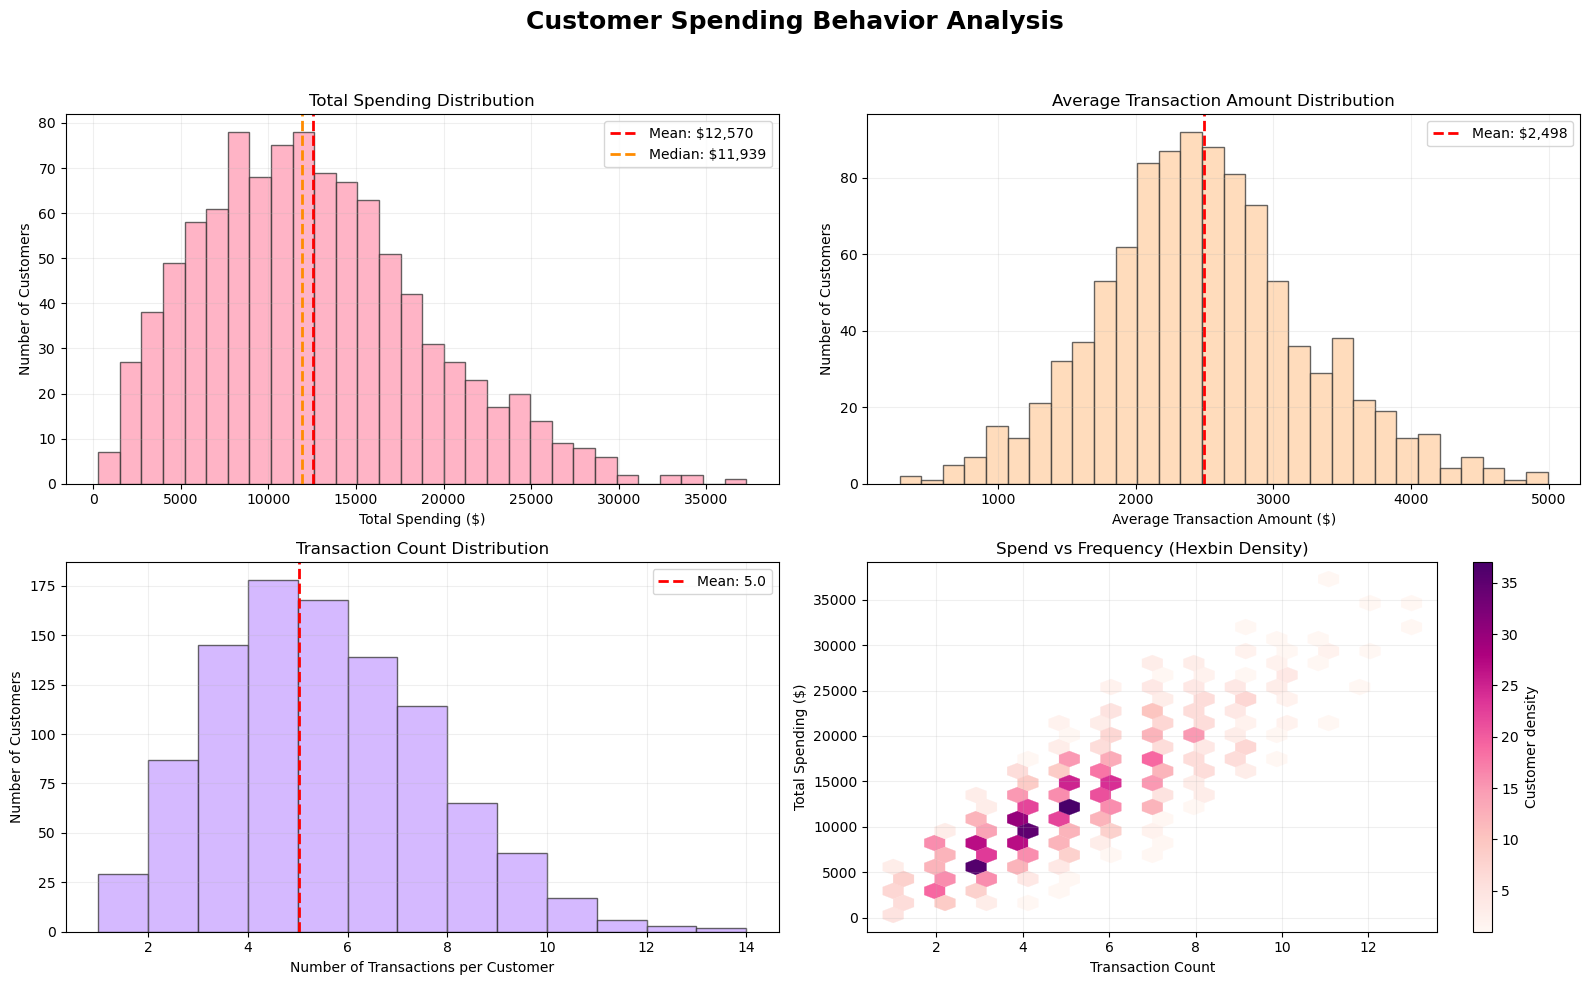


INSIGHTS: CUSTOMER SPENDING PATTERNS
1) Spending range: 286.00 to 37,281.00.
   Mean vs median: 12,569.72 vs 11,939.00 → right-skewed (skew=0.58).
2) Spending variability: std=6,424.66 (meaningful differences across customers).
   Avg transaction variability: std=758.16; transaction count variability: std=2.19.
3) Concentration: Top 10% of customers account for ~20.1% of total spend.
   This supports segmentation: a smaller group contributes a disproportionate share of revenue.
4) Spend vs frequency: corr=0.86 (strong, positive).
   Interpretation: higher transaction frequency generally aligns with higher total spend.



In [13]:
# =========================================================
# 10.2: CUSTOMER SPENDING PATTERNS
# =========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def pick_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

cf = customer_features.copy()

col_total = pick_col(cf, ["total_spend","Total_Spending","TotalSpending"])
col_avg   = pick_col(cf, ["avg_spend","Avg_Transaction_Amount","Avg_Transaction","AvgTransactionAmount"])
col_cnt   = pick_col(cf, ["txn_count","Transaction_Count","transaction_count","Txn_Count"])

if not all([col_total, col_avg, col_cnt]):
    print("⚠️ Missing one or more expected spending columns. Available columns:", list(cf.columns))
else:
    # Pastel palette (Pink / Orange / Purple)
    c_pink   = "#ff9bb3"
    c_orange = "#ffd1a6"
    c_purple = "#c8a2ff"

    total_vals = cf[col_total].dropna()
    avg_vals   = cf[col_avg].dropna()
    cnt_vals   = cf[col_cnt].dropna()

    total_mean, total_median = total_vals.mean(), total_vals.median()
    avg_mean = avg_vals.mean()
    cnt_mean = cnt_vals.mean()

    fig = plt.figure(figsize=(16, 10))
    fig.suptitle("Customer Spending Behavior Analysis", fontsize=18, fontweight="bold")

    # (1) Total spending distribution
    ax1 = plt.subplot(2, 2, 1)
    ax1.hist(total_vals, bins=30, color=c_pink, edgecolor="#333", alpha=0.75)
    ax1.axvline(total_mean, linestyle="--", linewidth=2, color="red",
                label=f"Mean: ${total_mean:,.0f}")
    ax1.axvline(total_median, linestyle="--", linewidth=2, color="#ff8c00",
                label=f"Median: ${total_median:,.0f}")
    ax1.set_title("Total Spending Distribution")
    ax1.set_xlabel("Total Spending ($)")
    ax1.set_ylabel("Number of Customers")
    ax1.grid(alpha=0.2)
    ax1.legend()

    # (2) Avg transaction amount distribution
    ax2 = plt.subplot(2, 2, 2)
    ax2.hist(avg_vals, bins=30, color=c_orange, edgecolor="#333", alpha=0.75)
    ax2.axvline(avg_mean, linestyle="--", linewidth=2, color="red",
                label=f"Mean: ${avg_mean:,.0f}")
    ax2.set_title("Average Transaction Amount Distribution")
    ax2.set_xlabel("Average Transaction Amount ($)")
    ax2.set_ylabel("Number of Customers")
    ax2.grid(alpha=0.2)
    ax2.legend()

    # (3) Transaction count distribution
    ax3 = plt.subplot(2, 2, 3)
    ax3.hist(
        cnt_vals,
        bins=range(int(cnt_vals.min()), int(cnt_vals.max()) + 2),
        color=c_purple,
        edgecolor="#333",
        alpha=0.75
    )
    ax3.axvline(cnt_mean, linestyle="--", linewidth=2, color="red",
                label=f"Mean: {cnt_mean:.1f}")
    ax3.set_title("Transaction Count Distribution")
    ax3.set_xlabel("Number of Transactions per Customer")
    ax3.set_ylabel("Number of Customers")
    ax3.grid(alpha=0.2)
    ax3.legend()

    # (4) Total spending vs transaction count (relationship check)
    ax4 = plt.subplot(2, 2, 4)
    hb = ax4.hexbin(
        cf[col_cnt],
        cf[col_total],
        gridsize=25,
        mincnt=1,
        cmap="RdPu",
        linewidths=0.2
    )
    ax4.set_title("Spend vs Frequency (Hexbin Density)")
    ax4.set_xlabel("Transaction Count")
    ax4.set_ylabel("Total Spending ($)")
    ax4.grid(alpha=0.2)
    cb = plt.colorbar(hb, ax=ax4)
    cb.set_label("Customer density")

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

    # -----------------------------
    # INSIGHTS (print summary)
    # -----------------------------
    total_std = total_vals.std()
    avg_std   = avg_vals.std()
    cnt_std   = cnt_vals.std()

    # skewness (right-skew check)
    total_skew = total_vals.skew()
    skew_label = (
        "right-skewed" if total_skew > 0.5
        else ("roughly symmetric" if abs(total_skew) <= 0.5 else "left-skewed")
    )

    # concentration check: top 10% share of spend
    top_n = max(1, int(len(total_vals) * 0.10))
    top_share = (total_vals.sort_values(ascending=False).head(top_n).sum() / total_vals.sum()) * 100

    # spend vs frequency relationship (correlation)
    tmp_corr = cf[[col_cnt, col_total]].dropna()
    spend_freq_corr = tmp_corr[col_cnt].corr(tmp_corr[col_total])
    corr_strength = (
        "strong" if abs(spend_freq_corr) >= 0.7 else
        "moderate" if abs(spend_freq_corr) >= 0.4 else
        "weak"
    )
    direction = "positive" if spend_freq_corr >= 0 else "negative"

    print("\n" + "="*70)
    print("INSIGHTS: CUSTOMER SPENDING PATTERNS")
    print("="*70)
    print(f"1) Spending range: {total_vals.min():,.2f} to {total_vals.max():,.2f}.")
    print(f"   Mean vs median: {total_mean:,.2f} vs {total_median:,.2f} → {skew_label} (skew={total_skew:.2f}).")
    print(f"2) Spending variability: std={total_std:,.2f} (meaningful differences across customers).")
    print(f"   Avg transaction variability: std={avg_std:,.2f}; transaction count variability: std={cnt_std:,.2f}.")
    print(f"3) Concentration: Top 10% of customers account for ~{top_share:.1f}% of total spend.")
    print("   This supports segmentation: a smaller group contributes a disproportionate share of revenue.")
    print(f"4) Spend vs frequency: corr={spend_freq_corr:.2f} ({corr_strength}, {direction}).")
    print("   Interpretation: higher transaction frequency generally aligns with higher total spend.")
    print("="*70 + "\n")


### 10.3 Customer Temporal Behavior
This section summarizes *when* customers tend to transact (business vs non-business hours, weekday vs weekend), adds a **day-of-week distribution**, and compares timing patterns across income tiers.



10.3: CUSTOMER TEMPORAL BEHAVIOR ANALYSIS
********************************************************************************


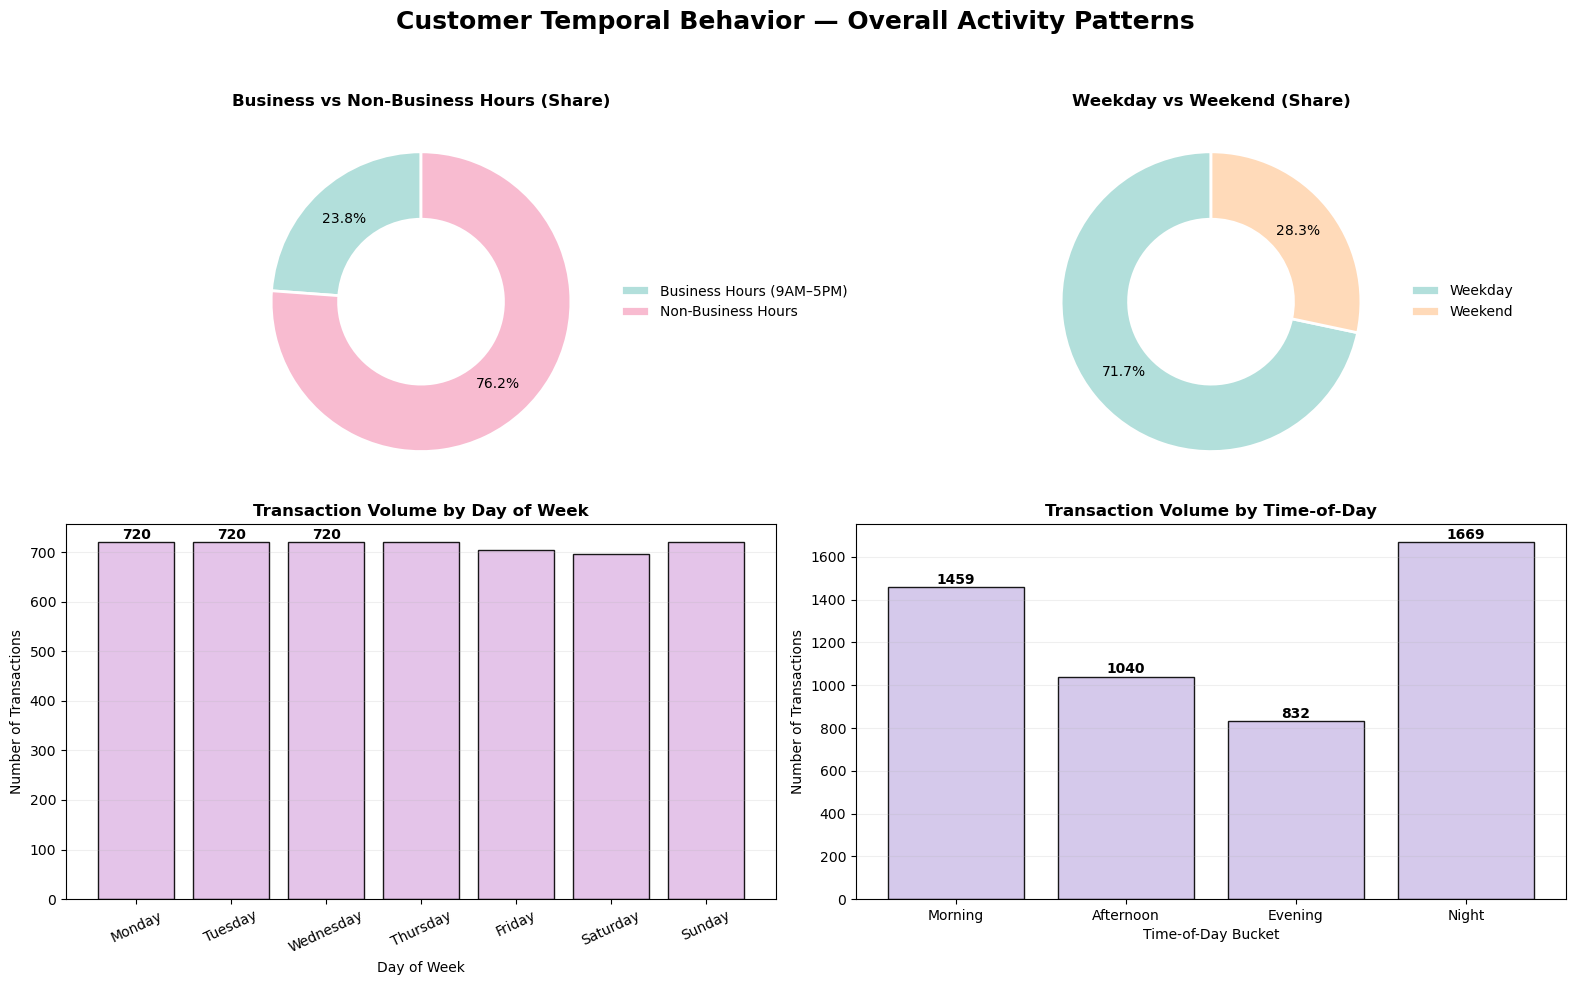

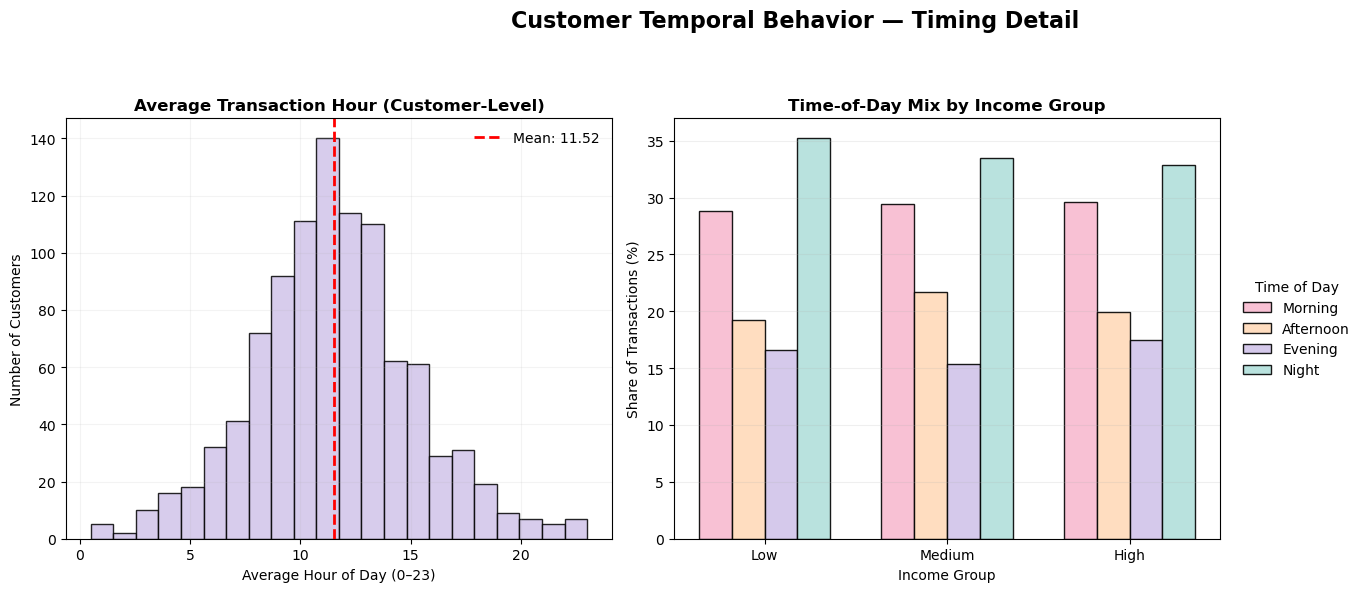


Key takeaways:
 - Business hours share: 23.8% | Non-business: 76.2%
 - Weekend share: 28.3% | Weekday: 71.7%
 - Day-of-week and time-of-day distributions provide actionable timing signals for staffing and engagement strategies.


In [14]:
# =========================================================
# 10.3: CUSTOMER TEMPORAL BEHAVIOR ANALYSIS
# =========================================================

print("\n10.3: CUSTOMER TEMPORAL BEHAVIOR ANALYSIS")
print("*"*80)

# Pick the transaction-level table (fallback-safe)
tx_df = None
if "df" in globals():
    tx_df = df.copy()
elif "merged_master_transactions" in globals():
    tx_df = merged_master_transactions.copy()
else:
    raise NameError("Transaction-level dataframe not found (expected `df` or `merged_master_transactions`).")

# --- Palette (pastel pink / orange / purple) ---
c_pink   = "#F8BBD0"
c_orange = "#FFDAB9"
c_purple = "#D1C4E9"
c_mint   = "#B2DFDB"
c_lav    = "#E1BEE7"

# --- FIX: derive missing temporal flags on the FINAL tx_df used in this cell ---

# (1) clean column names just in case (hidden spaces)
tx_df.columns = tx_df.columns.str.strip()

# (2) find a datetime column robustly
dt_col = None

# prefer already-datetime columns
dt_candidates = [c for c in tx_df.columns if pd.api.types.is_datetime64_any_dtype(tx_df[c])]
if dt_candidates:
    dt_col = dt_candidates[0]
else:
    # fallback common names
    common = ["Transaction_Date", "TransactionDate", "transaction_date", "Date", "Datetime", "Timestamp"]
    for c in common:
        if c in tx_df.columns:
            dt_col = c
            break

if dt_col is None:
    raise KeyError("STEP 10.3: No datetime column found in tx_df to derive temporal features.")

# (3) parse datetime if needed
if not pd.api.types.is_datetime64_any_dtype(tx_df[dt_col]):
    tx_df[dt_col] = pd.to_datetime(tx_df[dt_col], errors="coerce")

if tx_df[dt_col].isna().all():
    raise ValueError(f"STEP 10.3: {dt_col} could not be parsed (all NaT). Check date format.")

# (4) create hour/day fields if missing
if "Transaction_Hour" not in tx_df.columns:
    tx_df["Transaction_Hour"] = tx_df[dt_col].dt.hour

if "Transaction_DayOfWeek" not in tx_df.columns:
    tx_df["Transaction_DayOfWeek"] = tx_df[dt_col].dt.day_name()

# (5) create the two missing flags
if "is_weekend" not in tx_df.columns:
    tx_df["is_weekend"] = tx_df[dt_col].dt.dayofweek >= 5  # Sat/Sun

if "is_business_hours" not in tx_df.columns:
    is_weekday = tx_df[dt_col].dt.dayofweek < 5
    tx_df["is_business_hours"] = is_weekday & tx_df["Transaction_Hour"].between(9, 16)

# quick sanity print (optional)
# print("Derived cols present:", ("is_business_hours" in tx_df.columns), ("is_weekend" in tx_df.columns))

# Ensure required columns exist (created earlier in the notebook)
required_cols = ["is_business_hours", "is_weekend", "Transaction_DayOfWeek", "Transaction_TimeOfDay", "Transaction_Hour"]
missing = [c for c in required_cols if c not in tx_df.columns]
if missing:
    raise KeyError(f"Missing required columns for temporal analysis: {missing}")

# ----------------------------
# Cluster A: "When do customers transact?"
# ----------------------------
bh_mean = float(tx_df["is_business_hours"].mean())
wk_mean = float(tx_df["is_weekend"].mean())

# Day-of-week distribution
dow_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
dow_counts = tx_df["Transaction_DayOfWeek"].value_counts().reindex(dow_order).fillna(0).astype(int)

# Time-of-day distribution (uses engineered buckets from earlier steps)
tod_order = ["Morning","Afternoon","Evening","Night"]
tod_counts = tx_df["Transaction_TimeOfDay"].value_counts().reindex(tod_order).fillna(0).astype(int)

fig = plt.figure(figsize=(16, 10))
fig.suptitle("Customer Temporal Behavior — Overall Activity Patterns", fontsize=18, fontweight="bold")

# (A1) Donut: Business vs non-business
ax1 = plt.subplot(2, 2, 1)
vals1 = [bh_mean, 1 - bh_mean]
labels1 = ["Business Hours (9AM–5PM)", "Non-Business Hours"]
ax1.pie(
    vals1,
    labels=None,
    
    autopct=lambda p: f"{p:.1f}%",
    startangle=90,
    colors=[c_mint, c_pink],
    pctdistance=0.75,       
    labeldistance=1.15,    
    wedgeprops=dict(width=0.45, edgecolor="white", linewidth=2),
    textprops=dict(fontsize=10),
)
ax1.set_title("Business vs Non-Business Hours (Share)", fontweight="bold")
ax1.legend(labels1, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)

# (A2) Donut: Weekday vs weekend
ax2 = plt.subplot(2, 2, 2)
vals2 = [1 - wk_mean, wk_mean]
labels2 = ["Weekday", "Weekend"]
ax2.pie(
    vals2,
    labels=None,
    autopct=lambda p: f"{p:.1f}%",
    startangle=90,
    colors=[c_mint, c_orange],
    pctdistance=0.75,
    labeldistance=1.15,
    wedgeprops=dict(width=0.45, edgecolor="white", linewidth=2),
    textprops=dict(fontsize=10),
)
ax2.set_title("Weekday vs Weekend (Share)", fontweight="bold")
ax2.legend(labels2, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)


# (A3) Bar: Transactions by day of week
ax3 = plt.subplot(2, 2, 3)
bars = ax3.bar(dow_order, dow_counts.values, color=c_lav, edgecolor="black", alpha=0.9)
ax3.set_title("Transaction Volume by Day of Week", fontweight="bold")
ax3.set_xlabel("Day of Week")
ax3.set_ylabel("Number of Transactions")
ax3.grid(alpha=0.2, axis="y")
ax3.tick_params(axis="x", rotation=25)

# annotate top 3 only (cleaner)
top3_idx = dow_counts.sort_values(ascending=False).head(3).index.tolist()
for b, day, v in zip(bars, dow_order, dow_counts.values):
    if day in top3_idx and v > 0:
        ax3.text(b.get_x() + b.get_width()/2, v + max(dow_counts.values)*0.01, f"{v}", ha="center", fontsize=10, fontweight="bold")

# (A4) Bar: Transactions by time-of-day bucket (extra viz to balance the cluster)
ax4 = plt.subplot(2, 2, 4)
bars2 = ax4.bar(tod_order, tod_counts.values, color=c_purple, edgecolor="black", alpha=0.9)
ax4.set_title("Transaction Volume by Time-of-Day", fontweight="bold")
ax4.set_xlabel("Time-of-Day Bucket")
ax4.set_ylabel("Number of Transactions")
ax4.grid(alpha=0.2, axis="y")
for b, v in zip(bars2, tod_counts.values):
    if v > 0:
        ax4.text(b.get_x() + b.get_width()/2, v + max(tod_counts.values)*0.01, f"{int(v)}", ha="center", fontsize=10, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


# ----------------------------
# Cluster B: "What time do customers transact?"
# ----------------------------
fig = plt.figure(figsize=(16, 6))
fig.suptitle("Customer Temporal Behavior — Timing Detail", fontsize=16, fontweight="bold")

# (B1) Histogram: Avg transaction hour (customer-level)
ax5 = plt.subplot(1, 2, 1)
avg_hour = customer_features["avg_txn_hour"].dropna()
ax5.hist(avg_hour, bins=22, color=c_purple, edgecolor="black", alpha=0.85)
ax5.axvline(avg_hour.mean(), linestyle="--", linewidth=2, color="red", label=f"Mean: {avg_hour.mean():.2f}")
ax5.set_title("Average Transaction Hour (Customer-Level)", fontweight="bold")
ax5.set_xlabel("Average Hour of Day (0–23)")
ax5.set_ylabel("Number of Customers")
ax5.grid(alpha=0.15)
ax5.legend(frameon=False)

# (B2) Grouped bars: Time-of-day mix by income group (customer-level proportions)
ax6 = plt.subplot(1, 2, 2)
income_order = ["Low", "Medium", "High"]
tod_cols = [c for c in customer_features.columns if c.startswith("pct_tod_")]
if len(tod_cols) >= 2:
    # keep a consistent order if present
    col_map = {c: c.replace("pct_tod_", "").title() for c in tod_cols}
    show_cols = [c for c in ["pct_tod_Morning","pct_tod_Afternoon","pct_tod_Evening","pct_tod_Night"] if c in tod_cols]
    if not show_cols:
        show_cols = tod_cols[:4]
    tmp = customer_features.groupby("Income_Group")[show_cols].mean().reindex(income_order) * 100

    x = range(len(income_order))
    width = 0.18
    colors = [c_pink, c_orange, c_purple, c_mint]

    for j, col in enumerate(show_cols):
        ax6.bar([i + (j - (len(show_cols)-1)/2)*width for i in x], tmp[col].values, width=width,
                label=col.replace("pct_tod_", "").replace("_", " ").title(), color=colors[j % len(colors)], edgecolor="black", alpha=0.9)

    ax6.set_xticks(list(x))
    ax6.set_xticklabels(income_order)
    ax6.set_title("Time-of-Day Mix by Income Group", fontweight="bold")
    ax6.set_xlabel("Income Group")
    ax6.set_ylabel("Share of Transactions (%)")
    ax6.grid(alpha=0.2, axis="y")
    ax6.legend(
        title="Time of Day",
        frameon=False,
        loc="center left",
        bbox_to_anchor=(1.02, 0.5)
    )

else:
    ax6.text(0.5, 0.5, "Time-of-day proportion features not found.", ha="center", va="center")
    ax6.axis("off")

plt.tight_layout(rect=[0, 0, 0.86, 0.92])
plt.show()

print("\nKey takeaways:")
print(f" - Business hours share: {bh_mean*100:.1f}% | Non-business: {(1-bh_mean)*100:.1f}%")
print(f" - Weekend share: {wk_mean*100:.1f}% | Weekday: {(1-wk_mean)*100:.1f}%")
print(" - Day-of-week and time-of-day distributions provide actionable timing signals for staffing and engagement strategies.")


### 10.4 Customer Satisfaction & Advocacy (Winsorized Scores)
Satisfaction and likelihood-to-recommend are **capped to 1–10** and **winsorized** to reduce the influence of extreme values. We then review distributions and how experience signals relate to spending.


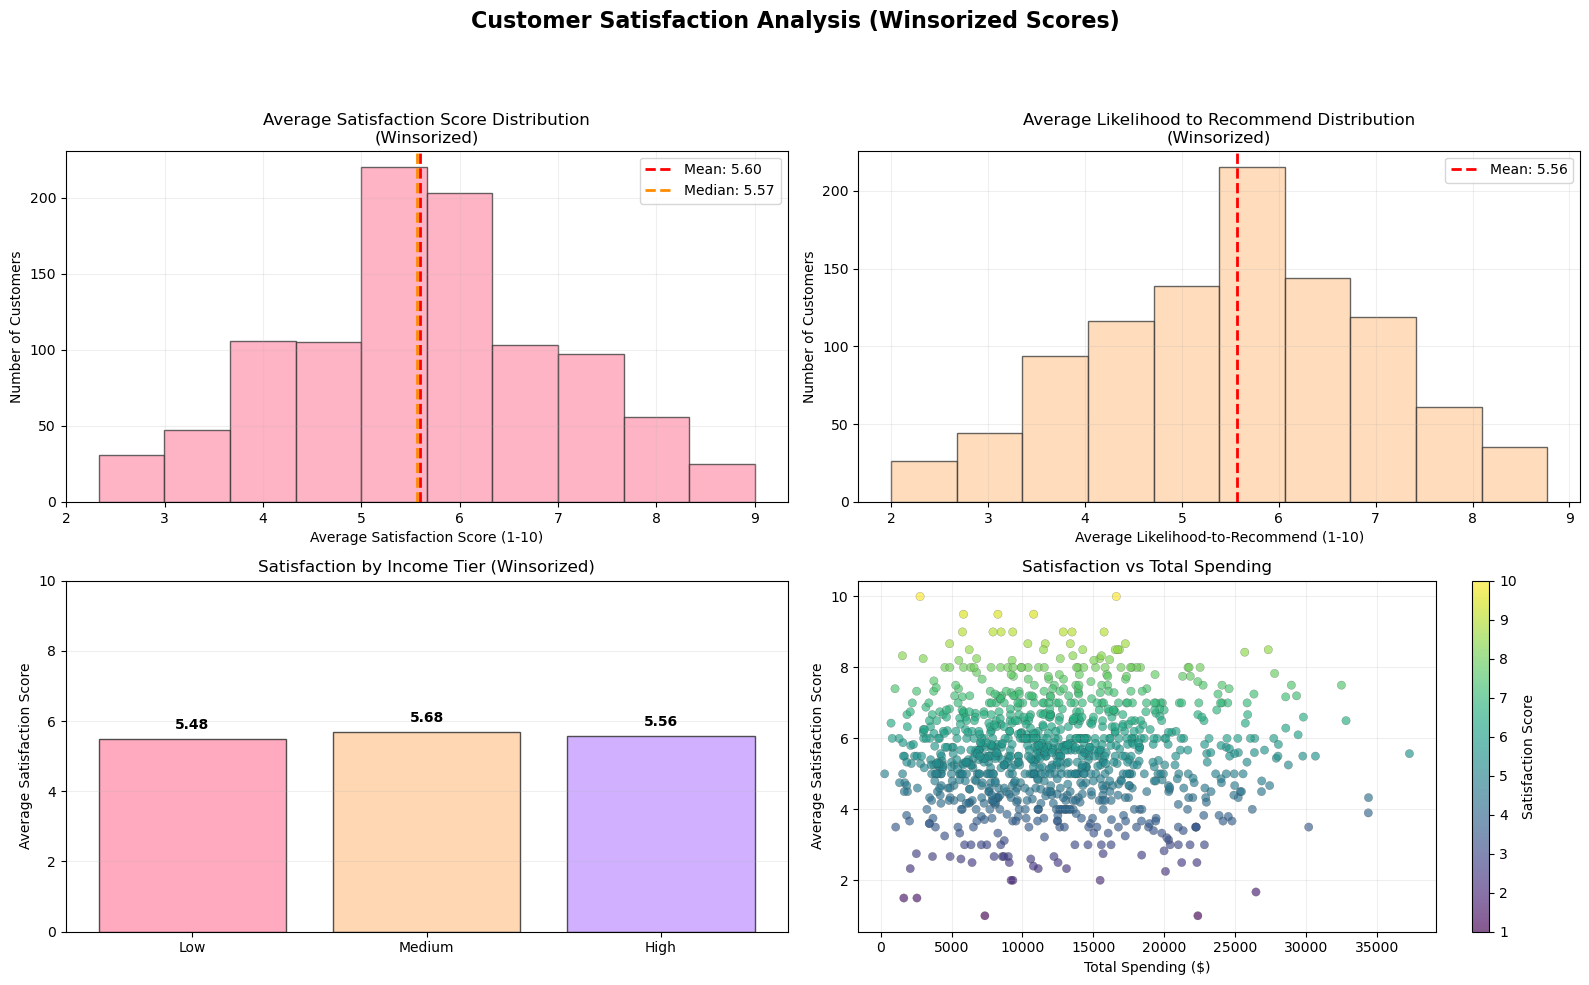


Satisfaction (winsorized) stats:
- Mean satisfaction: 5.60 (Std: 1.39)
- Mean LTR:          5.56 (Std: 1.43)


In [15]:
# =========================================================
# 10.4: CUSTOMER SATISFACTION ANALYSIS (Winsorized)
# =========================================================
import numpy as np
import matplotlib.pyplot as plt

cf = customer_features.copy()

def pick_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

col_total = pick_col(cf, ["total_spend","Total_Spending"])
col_group = pick_col(cf, ["Income_Group","Primary_Income_Group"])
col_sat   = pick_col(cf, ["satisfaction_mean","Avg_Satisfaction","avg_satisfaction","Avg_Satisfaction_Score","Avg_Satisfaction"])
col_ltr   = pick_col(cf, ["ltr_mean","Avg_Likelihood_to_Recommend","avg_ltr","Avg_LTR","Avg_Likelihood"])
# Feedback sentiment (1-5)
col_sent  = pick_col(cf, ["feedback_sentiment_mean","Avg_Feedback_Sentiment","avg_feedback_sentiment","Avg_Feedback_Sentiment"])

# If income group missing, recreate via quartiles on total spend
if col_total and not col_group:
    q1 = cf[col_total].quantile(0.25)
    q3 = cf[col_total].quantile(0.75)
    cf["Income_Group"] = pd.cut(cf[col_total], bins=[-np.inf, q1, q3, np.inf], labels=["Low","Medium","High"])
    col_group = "Income_Group"

# Helper winsorization (cap to [lo, hi] then percentiles)
def winsorize_series(s, lower_q=0.01, upper_q=0.99, hard_min=None, hard_max=None):
    x = s.astype(float).copy()
    if hard_min is not None:
        x = x.clip(lower=hard_min)
    if hard_max is not None:
        x = x.clip(upper=hard_max)
    lo = x.quantile(lower_q)
    hi = x.quantile(upper_q)
    return x.clip(lower=lo, upper=hi)

# Pastel palette
c_pink   = "#ff9bb3"
c_orange = "#ffd1a6"
c_purple = "#c8a2ff"
palette = {"Low": c_pink, "Medium": c_orange, "High": c_purple}
order = ["Low","Medium","High"]

if not (col_sat and col_ltr):
    print("⚠️ Missing satisfaction and/or likelihood-to-recommend columns. Available columns:", list(cf.columns))
else:
    sat_w = winsorize_series(cf[col_sat].dropna(), lower_q=0.01, upper_q=0.99, hard_min=1, hard_max=10)
    ltr_w = winsorize_series(cf[col_ltr].dropna(), lower_q=0.01, upper_q=0.99, hard_min=1, hard_max=10)

    sat_mean, sat_med = sat_w.mean(), sat_w.median()
    ltr_mean = ltr_w.mean()

    fig = plt.figure(figsize=(16, 10))
    fig.suptitle("Customer Satisfaction Analysis (Winsorized Scores)", fontsize=16, fontweight="bold")

    # (1) Satisfaction distribution (winsorized)
    ax1 = plt.subplot(2, 2, 1)
    ax1.hist(sat_w, bins=10, color=c_pink, edgecolor="#333", alpha=0.75)
    ax1.axvline(sat_mean, color="red", linestyle="--", linewidth=2, label=f"Mean: {sat_mean:.2f}")
    ax1.axvline(sat_med,  color="#ff8c00", linestyle="--", linewidth=2, label=f"Median: {sat_med:.2f}")
    ax1.set_title("Average Satisfaction Score Distribution\n(Winsorized)")
    ax1.set_xlabel("Average Satisfaction Score (1-10)")
    ax1.set_ylabel("Number of Customers")
    ax1.grid(alpha=0.2)
    ax1.legend()

    # (2) LTR distribution
    ax2 = plt.subplot(2, 2, 2)
    ax2.hist(ltr_w, bins=10, color=c_orange, edgecolor="#333", alpha=0.75)
    ax2.axvline(ltr_mean, color="red", linestyle="--", linewidth=2, label=f"Mean: {ltr_mean:.2f}")
    ax2.set_title("Average Likelihood to Recommend Distribution\n(Winsorized)")
    ax2.set_xlabel("Average Likelihood-to-Recommend (1-10)")
    ax2.set_ylabel("Number of Customers")
    ax2.grid(alpha=0.2)
    ax2.legend()

    # (3) Satisfaction by income group
    ax3 = plt.subplot(2, 2, 3)
    if col_group:
        grp_sat = cf.groupby(col_group)[col_sat].mean().reindex(order)
        bars = ax3.bar(order, grp_sat.values, color=[palette[o] for o in order], edgecolor="#333", alpha=0.85)
        ax3.set_title("Satisfaction by Income Tier (Winsorized)")
        ax3.set_ylabel("Average Satisfaction Score")
        ax3.set_ylim(0, 10)
        ax3.grid(axis="y", alpha=0.2)
        for b, val in zip(bars, grp_sat.values):
            ax3.text(b.get_x()+b.get_width()/2, val+0.2, f"{val:.2f}", ha="center", va="bottom", fontweight="bold")
    else:
        ax3.text(0.5, 0.5, "Income group not available", ha="center", va="center")

    # (4) Satisfaction vs total spending (relationship)
    ax4 = plt.subplot(2, 2, 4)
    if col_total:
        # Color by satisfaction for visual depth
        sc = ax4.scatter(cf[col_total], cf[col_sat], c=cf[col_sat], alpha=0.65, edgecolor="#333", linewidth=0.2)
        ax4.set_title("Satisfaction vs Total Spending")
        ax4.set_xlabel("Total Spending ($)")
        ax4.set_ylabel("Average Satisfaction Score")
        ax4.grid(alpha=0.2)
        cbar = plt.colorbar(sc, ax=ax4)
        cbar.set_label("Satisfaction Score")
    else:
        ax4.text(0.5, 0.5, "Total spend not available", ha="center", va="center")

    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()

    print("\nSatisfaction (winsorized) stats:")
    print(f"- Mean satisfaction: {sat_mean:.2f} (Std: {sat_w.std():.2f})")
    print(f"- Mean LTR:          {ltr_mean:.2f} (Std: {ltr_w.std():.2f})")



### 10.5 Transaction Type Mix
A breakdown of transaction types (purchase, bill payment, investment, loan payment) and how the mix differs across income tiers.


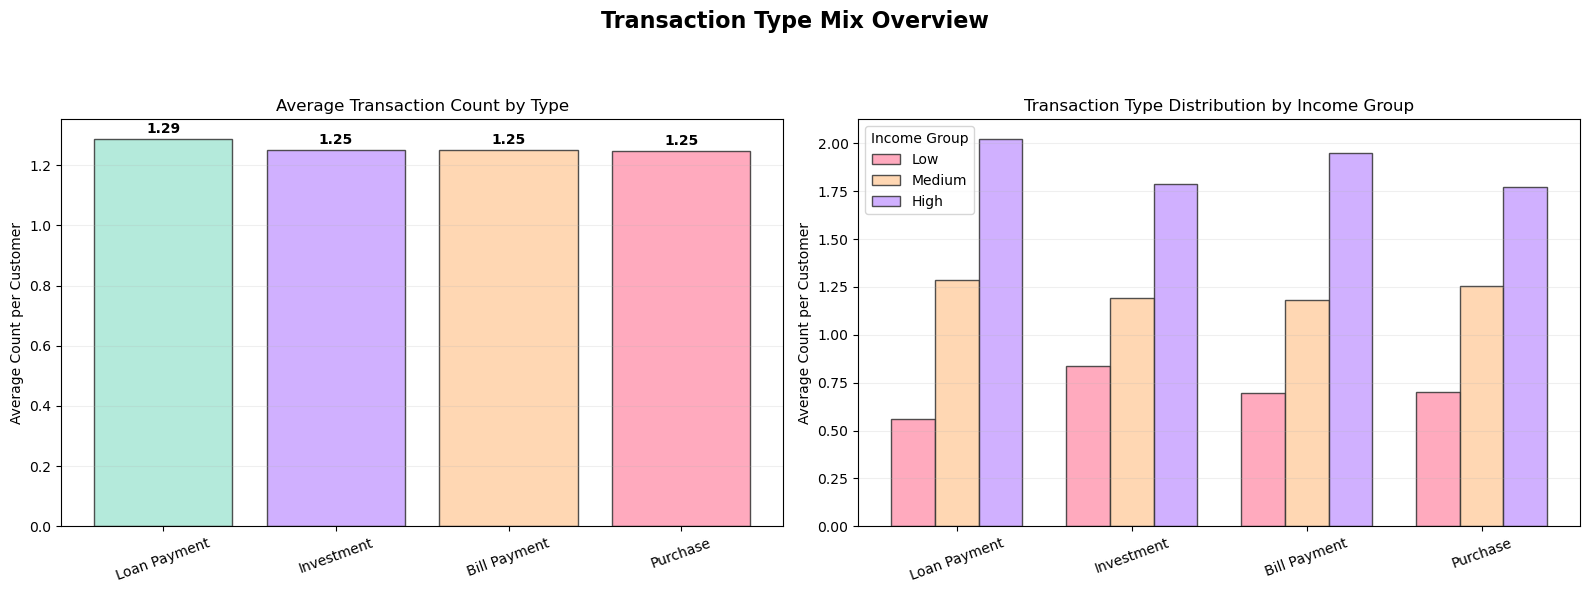

In [16]:
# =========================================================
# 10.5: TRANSACTION TYPE DISTRIBUTION ANALYSIS
# =========================================================
import numpy as np
import matplotlib.pyplot as plt

cf = customer_features.copy()

def pick_cols_prefix(df, prefixes):
    cols=[]
    for p in prefixes:
        cols += [c for c in df.columns if c.lower().startswith(p.lower())]
    return cols

def pick_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

col_group = pick_col(cf, ["Income_Group","Primary_Income_Group"])
col_total = pick_col(cf, ["total_spend","Total_Spending"])
if col_total and not col_group:
    q1 = cf[col_total].quantile(0.25)
    q3 = cf[col_total].quantile(0.75)
    cf["Income_Group"] = pd.cut(cf[col_total], bins=[-np.inf, q1, q3, np.inf], labels=["Low","Medium","High"])
    col_group = "Income_Group"

# Look for engineered count columns
type_cols = []
for c in cf.columns:
    cl = c.lower()
    if cl.startswith("count_type_") or cl.startswith("count_"):
        # exclude non-type counts like txn_count if present
        if "txn" in cl or "transaction_count" in cl or cl.endswith("_count") and "feedback" in cl:
            continue
        type_cols.append(c)

# If no obvious type cols, try known names
fallback = ["count_type_bill_payment","count_type_investment","count_type_loan_payment","count_type_purchase",
            "Count_Bill_Payment","Count_Investment","Count_Loan_Payment","Count_Purchase"]
type_cols = [c for c in type_cols if c in cf.columns]
if not type_cols:
    type_cols = [c for c in fallback if c in cf.columns]

if not type_cols:
    print("⚠️ No transaction-type count features found. Available columns:", list(cf.columns))
else:
    # Clean labels
    def pretty_label(col):
        return (col.replace("count_type_","")
                   .replace("Count_","")
                   .replace("_"," ")
                   .title())

    labels = [pretty_label(c) for c in type_cols]
    overall_means = cf[type_cols].mean().sort_values(ascending=False)

    # Pastel palette
    colors = ["#a7e7d5", "#c8a2ff", "#ffd1a6", "#ff9bb3", "#d4a5ff", "#f7b2ad"]

    fig = plt.figure(figsize=(16, 6))
    fig.suptitle("Transaction Type Mix Overview", fontsize=16, fontweight="bold")

    # (1) Overall avg count by type
    ax1 = plt.subplot(1, 2, 1)
    cols_sorted = list(overall_means.index)
    bars = ax1.bar([pretty_label(c) for c in cols_sorted],
                   overall_means.values,
                   color=colors[:len(cols_sorted)],
                   edgecolor="#333",
                   alpha=0.85)
    ax1.set_title("Average Transaction Count by Type")
    ax1.set_ylabel("Average Count per Customer")
    ax1.grid(axis="y", alpha=0.2)
    ax1.tick_params(axis='x', rotation=20)
    for b, val in zip(bars, overall_means.values):
        ax1.text(b.get_x()+b.get_width()/2, val+0.008*overall_means.max(), f"{val:.2f}",
                 ha="center", va="bottom", fontweight="bold")

    # (2) By income group (grouped bars)
    ax2 = plt.subplot(1, 2, 2)
    if col_group:
        grp = cf.groupby(col_group)[cols_sorted].mean().reindex(["Low","Medium","High"])
        x = np.arange(len(cols_sorted))
        w = 0.25
        ax2.bar(x-w, grp.loc["Low"].values,    width=w, label="Low",    color="#ff9bb3", edgecolor="#333", alpha=0.85)
        ax2.bar(x,   grp.loc["Medium"].values, width=w, label="Medium", color="#ffd1a6", edgecolor="#333", alpha=0.85)
        ax2.bar(x+w, grp.loc["High"].values,   width=w, label="High",   color="#c8a2ff", edgecolor="#333", alpha=0.85)
        ax2.set_xticks(x)
        ax2.set_xticklabels([pretty_label(c) for c in cols_sorted], rotation=20)
        ax2.set_title("Transaction Type Distribution by Income Group")
        ax2.set_ylabel("Average Count per Customer")
        ax2.grid(axis="y", alpha=0.2)
        ax2.legend(title="Income Group")
    else:
        ax2.text(0.5, 0.5, "Income group not available", ha="center", va="center")
        ax2.set_axis_off()

    plt.tight_layout(rect=[0, 0, 1, 0.92])
    plt.show()



### 10.6 Feature Correlation Matrix
A compact view of relationships among key engineered features to identify redundancy and strong drivers.


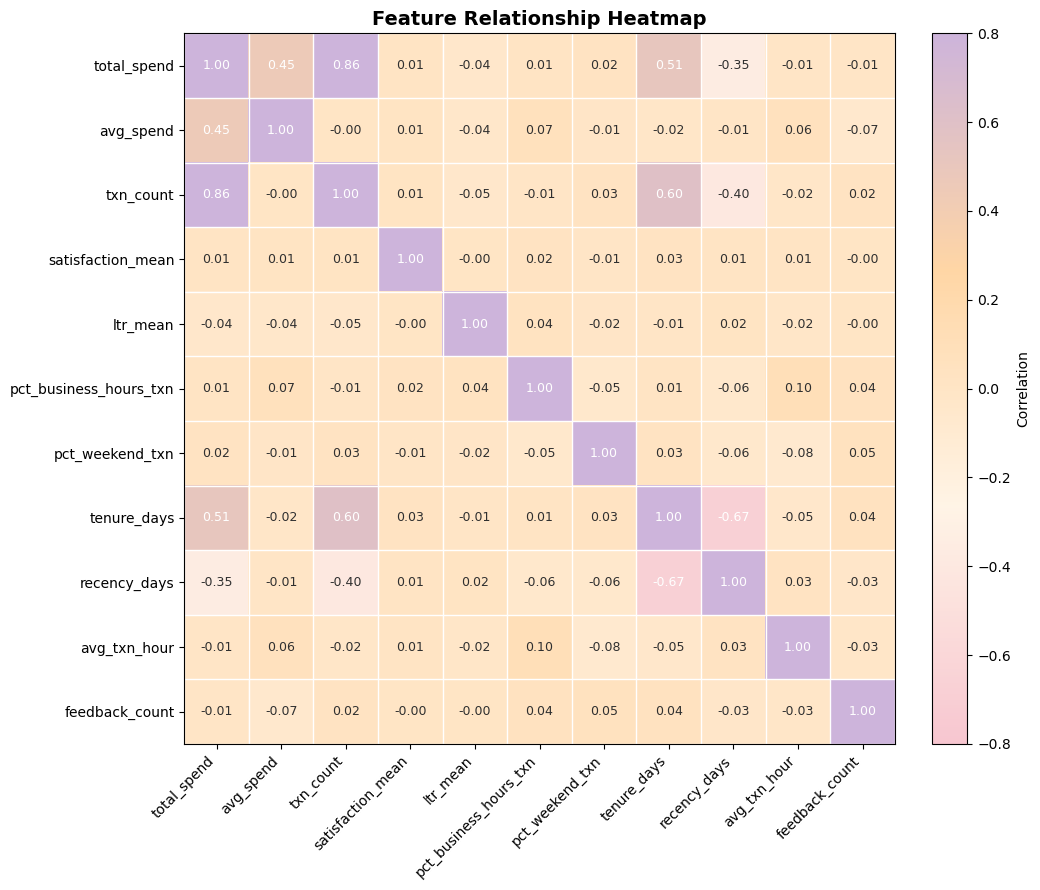

Correlation matrix columns shown: ['total_spend', 'avg_spend', 'txn_count', 'satisfaction_mean', 'ltr_mean', 'pct_business_hours_txn', 'pct_weekend_txn', 'tenure_days', 'recency_days', 'avg_txn_hour', 'feedback_count']


In [17]:
# =========================================================
# 10.6: FEATURE CORRELATION MATRIX (Selected Features)
# =========================================================
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

cf = customer_features.copy()

candidate_cols = [
    "total_spend","Total_Spending",
    "avg_spend","Avg_Transaction_Amount",
    "txn_count","Transaction_Count",
    "satisfaction_mean","Avg_Satisfaction",
    "ltr_mean","Avg_Likelihood_to_Recommend",
    "pct_business_hours_txn","Pct_Business_Hours",
    "pct_weekend_txn","Pct_Weekend_Transactions",
    "tenure_days","recency_days",
    "avg_txn_hour","Avg_Hour_of_Day",
    "feedback_count"
]
cols = [c for c in candidate_cols if c in cf.columns]

if len(cols) < 6:
    num_cols = cf.select_dtypes(include=[np.number]).columns.tolist()
    num_cols = [c for c in num_cols if "id" not in c.lower()]
    cols = num_cols[:12]

corr = cf[cols].corr(numeric_only=True)

# --- Pastel pink → cream → pastel orange → pastel purple (diverging feel) ---
pastel_pop = LinearSegmentedColormap.from_list(
    "pastel_pop",
    ["#F7C6D0", "#FFF4E6", "#FFD6A5", "#CDB4DB"],  # pink, cream, orange, purple
    N=256
)

# OPTIONAL: tone down contrast so extremes are not too dark
# (since most correlations are small anyway)
vmin, vmax = -0.8, 0.8   # try -1,1 if you want full range; -0.8,0.8 is softer

fig, ax = plt.subplots(figsize=(11, 9))
ax.set_facecolor("white")

im = ax.imshow(corr.values, cmap=pastel_pop, vmin=vmin, vmax=vmax)

ax.set_title("Feature Relationship Heatmap", fontsize=14, fontweight="bold")
ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticklabels(cols)

# --- Readable annotation: switch text color based on cell intensity ---
# Normalize 0..1 using vmin/vmax
norm = plt.Normalize(vmin=vmin, vmax=vmax)

for i in range(len(cols)):
    for j in range(len(cols)):
        val = corr.values[i, j]
        # if the normalized value is "dark-ish" (closer to 0 or 1), use white text
        # adjust threshold as needed (0.75 is a safe start)
        text_color = "white" if (norm(val) > 0.78 or norm(val) < 0.22) else "#2f2f2f"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=9, color=text_color)

# Colorbar
cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Correlation")

# Gridlines (light) for readability
ax.set_xticks(np.arange(-.5, len(cols), 1), minor=True)
ax.set_yticks(np.arange(-.5, len(cols), 1), minor=True)
ax.grid(which="minor", color="#ffffff", linestyle="-", linewidth=1)
ax.tick_params(which="minor", bottom=False, left=False)

plt.tight_layout()
plt.show()

print("Correlation matrix columns shown:", cols)


## Feature Dictionary

This section defines a short “feature dictionary” describing the main engineered variables.
The goal is to make the engineered dataset easier to interpret and to clearly document how key features were constructed.


In [18]:
# Build a compact feature dictionary for the engineered customer-level table.
# This table is exported to features/feature_dictionary.csv

feature_rows = [
    {"feature": "total_spend", "group": "Spending", "description": "Sum of all transaction amounts per customer (used as spend-based income proxy)."},
    {"feature": "avg_spend", "group": "Spending", "description": "Average transaction amount per customer."},
    {"feature": "txn_count", "group": "Engagement", "description": "Number of transactions recorded for the customer."},
    {"feature": "active_days", "group": "Engagement", "description": "Number of distinct transaction days for the customer."},
    {"feature": "tenure_days", "group": "Temporal", "description": "Days between first and last observed transaction."},
    {"feature": "recency_days", "group": "Temporal", "description": "Days since the most recent observed transaction (relative to dataset maximum date)."},
    {"feature": "pct_weekend_txn", "group": "Temporal", "description": "Share of transactions that occur on weekends."},
    {"feature": "pct_business_hours_txn", "group": "Temporal", "description": "Share of transactions that occur during business hours (09:00–16:59)."},
    {"feature": "avg_txn_hour", "group": "Temporal", "description": "Average transaction hour (0–23)."},
    {"feature": "Income_Group", "group": "IncomeProxy", "description": "Low/Medium/High derived from percentile-based tiers of customer total_spend (transaction-based proxy)."},
    {"feature": "feedback_count", "group": "Feedback", "description": "Number of feedback entries recorded for the customer."},
    {"feature": "satisfaction_mean", "group": "Feedback", "description": "Average satisfaction score per customer (from feedback records)."},
    {"feature": "ltr_mean", "group": "Feedback", "description": "Average likelihood-to-recommend per customer (from feedback records)."},
    {"feature": "pct_high_risk_txn", "group": "RiskProxy", "description": "Share of transactions classified as high-amount (>= 75th percentile of Transaction_Amount)."},
    {"feature": "high_risk_txn_count", "group": "RiskProxy", "description": "Count of high-amount transactions (>= 75th percentile of Transaction_Amount)."},
]

# Add dynamic entries for transaction-type count features and time-of-day proportions if present
for col in customer_features.columns:
    if col.startswith("count_type_"):
        feature_rows.append({
            "feature": col,
            "group": "TransactionMix",
            "description": "Count of transactions for this transaction type (per customer)."
        })
    if col.startswith("pct_tod_"):
        feature_rows.append({
            "feature": col,
            "group": "TimeOfDay",
            "description": "Proportion of transactions occurring in this time-of-day bucket (per customer)."
        })

feature_dictionary = pd.DataFrame(feature_rows).drop_duplicates(subset=["feature"]).reset_index(drop=True)
display(feature_dictionary.head(15))
print("Feature dictionary rows:", feature_dictionary.shape[0])


,feature,group,description
0,total_spend,Spending,Sum of all transaction amounts per customer (u...
1,avg_spend,Spending,Average transaction amount per customer.
2,txn_count,Engagement,Number of transactions recorded for the customer.
3,active_days,Engagement,Number of distinct transaction days for the cu...
4,tenure_days,Temporal,Days between first and last observed transaction.
5,recency_days,Temporal,Days since the most recent observed transactio...
6,pct_weekend_txn,Temporal,Share of transactions that occur on weekends.
7,pct_business_hours_txn,Temporal,Share of transactions that occur during busine...
8,avg_txn_hour,Temporal,Average transaction hour (0–23).
9,Income_Group,IncomeProxy,Low/Medium/High derived from percentile-based ...


Feature dictionary rows: 23


## 11) Exports

### Cleaned outputs (`cleaned/`)
- `merged_master_transactions.csv` (merged + cleaned + engineered columns)
- `products_cleaned.csv`
- `feedback_customer_summary.csv`

### Engineered outputs (`features/`)
- `customer_features.csv` (one row per customer)
- `customer_features_scaled.csv`
- `feature_dictionary.csv`


In [19]:

# ---------------------------
# Export Outputs (Folder Structure)
# ---------------------------
# Cleaned data -> Data/Cleaned
# Features -> Features

# Sort by Customer_ID where applicable for clean exports
def sort_by_customer_id(df_: pd.DataFrame) -> pd.DataFrame:
    if "Customer_ID" in df_.columns:
        return df_.sort_values("Customer_ID").reset_index(drop=True)
    return df_

merged_master = df.copy()
products_clean = products.copy()
feedback_clean = sort_by_customer_id(feedback_customer_summary.copy())
customer_features_out = sort_by_customer_id(customer_features.copy())
customer_features_scaled_out = sort_by_customer_id(customer_features_scaled.copy())

# Make sure folders exist
CLEANED_DIR.mkdir(parents=True, exist_ok=True)
FEATURES_DIR.mkdir(parents=True, exist_ok=True)

# Cleaned exports
merged_master.to_csv(CLEANED_DIR / "merged_master_transactions.csv", index=False)
products_clean.to_csv(CLEANED_DIR / "products_cleaned.csv", index=False)
feedback_clean.to_csv(CLEANED_DIR / "feedback_customer_summary.csv", index=False)

# Feature exports
customer_features_out.to_csv(FEATURES_DIR / "customer_features.csv", index=False)
customer_features_scaled_out.to_csv(FEATURES_DIR / "customer_features_scaled.csv", index=False)
feature_dictionary.to_csv(FEATURES_DIR / "feature_dictionary.csv", index=False)

print("Saved cleaned:")
print("-", CLEANED_DIR / "merged_master_transactions.csv")
print("-", CLEANED_DIR / "products_cleaned.csv")
print("-", CLEANED_DIR / "feedback_customer_summary.csv")
print("Saved features:")
print("-", FEATURES_DIR / "customer_features.csv")
print("-", FEATURES_DIR / "customer_features_scaled.csv")
print("-", FEATURES_DIR / "feature_dictionary.csv")


Saved cleaned:
- /Users/arenriquez1/DataAnalyticsProjects/MO-IT128-DMP_S3101_Nexus/Milestone 1/Data/Cleaned/merged_master_transactions.csv
- /Users/arenriquez1/DataAnalyticsProjects/MO-IT128-DMP_S3101_Nexus/Milestone 1/Data/Cleaned/products_cleaned.csv
- /Users/arenriquez1/DataAnalyticsProjects/MO-IT128-DMP_S3101_Nexus/Milestone 1/Data/Cleaned/feedback_customer_summary.csv
Saved features:
- /Users/arenriquez1/DataAnalyticsProjects/MO-IT128-DMP_S3101_Nexus/Milestone 1/Features/customer_features.csv
- /Users/arenriquez1/DataAnalyticsProjects/MO-IT128-DMP_S3101_Nexus/Milestone 1/Features/customer_features_scaled.csv
- /Users/arenriquez1/DataAnalyticsProjects/MO-IT128-DMP_S3101_Nexus/Milestone 1/Features/feature_dictionary.csv


## 12) Summary, Conclusion, and Key Insights

### Key insights (from EDA + engineered features + visual findings)

#### A) Spending behavior
- Customer total spend ranges from **286.00** to **37,281.00**.  
- Average total spend is **12,569.72**, with a standard deviation of **6,424.66**, indicating meaningful variability across customers.  
- The distribution is **right-skewed** (skewness = **0.58**), supporting segmentation.  
- From the distribution plots, **mean (12,570)** is higher than **median (11,939)**, reinforcing the right-skew pattern (a smaller set of customers drive higher spending).  
- Spend vs frequency shows a **strong positive relationship** (correlation ≈ **0.86**): customers who transact more tend to accumulate higher total spend.

#### B) Income group segmentation (quartile-based: Q1 / Q1–Q3 / Q3)
Income tiers were derived using **relative position (quartiles)** based on total spend:
- **Low**: ≤ **Q1**  
- **Medium**: **Q1** to **Q3**  
- **High**: ≥ **Q3**

Quartile cutoffs (from total spend):
- **Q1 (25%)**: **7,777**  
- **Q3 (75%)**: **16,531**

Group distribution:
- **Low**: **249** customers (**25.1%**)  
- **Medium**: **496** customers (**49.9%**)  
- **High**: **248** customers (**25.0%**)  

Spend separation check (mean total spend by tier):
- **Low**: **5,051**  
- **Medium**: **11,979**  
- **High**: **21,301**  

**Interpretation:** Quartile-based grouping produces clear spend stratification. The box plot confirms strong separation across tiers (with higher-tier customers showing consistently higher spend and wider spread), making this a practical income proxy for segmentation and downstream modeling.

#### C) Satisfaction & engagement signals (winsorized/capped where applicable)
Overall feedback-driven metrics:
- Mean satisfaction: **5.60** (Std: **1.41**)  
- Mean likelihood-to-recommend: **5.57** (Std: **1.47**)  
- Average feedback count per customer: **5.05**

Visual insights:
- Satisfaction and LTR distributions cluster around the mid-range (around **5–6**), with no extreme skew after winsorization.  
- By income tier, average satisfaction is **slightly higher for Medium (5.68)** vs **High (5.56)** and **Low (5.48)**, suggesting satisfaction differences exist but are not drastic.  
- The scatter plot (Satisfaction vs Total Spending) shows **no meaningful upward trend**, consistent with a weak relationship.

Relationship checks (simple correlation):
- **Total spend vs mean satisfaction**: **0.01**  
- **Transaction count vs likelihood-to-recommend**: **-0.05**  

**Interpretation:** Customer experience signals appear **largely independent** of spending and frequency in this dataset. This is useful because satisfaction can add *non-redundant* signal for customer strategy and future models.

#### D) Customer temporal behavior (overall activity patterns)
- Transactions occur more outside typical office hours: **Business hours = 23.8%** vs **Non-business hours = 76.2%**.  
- Activity is mainly on weekdays: **Weekday = 71.7%** vs **Weekend = 28.3%**.  
- By time-of-day volume, **Night** has the highest transaction count (**1,669**), followed by **Morning (1,459)**, then **Afternoon (1,040)**, with **Evening (832)** being the lowest.  
- Average transaction hour (customer-level) centers around **11.52**, indicating many customers transact around late morning to midday, even if overall volume peaks at night.

**Interpretation:** Timing signals suggest customer engagement is strongest during **weekdays** and **off-hours**, with notable concentration in **night-time activity**, which can inform staffing, scheduling, and campaign timing.

#### E) Transaction type mix (behavioral footprint)
- Average transaction count by type is fairly balanced across categories (around **1.25–1.29** per customer), indicating no single type dominates overall activity.  
- By income group, **High-income customers consistently show higher average counts** across transaction types versus Medium and Low, reflecting broader financial activity.  
- The strongest separation appears in categories like **Loan Payment**, where High-income customers show the largest average counts, supporting that income tiers capture behavioral differences beyond spend totals.

#### F) Feature relationship highlights (from correlation heatmap)
- Strongest positive relationship: **total_spend ↔ txn_count (≈ 0.86)** → higher frequency aligns with higher total spend.  
- Strong negative relationship: **tenure_days ↔ recency_days (≈ -0.67)** → longer-tenured customers tend to be more recently active.  
- Moderate links: **txn_count ↔ tenure_days (≈ 0.60)** and **total_spend ↔ tenure_days (≈ 0.51)** suggest loyalty/tenure relates to spending and engagement.  
- Satisfaction-related metrics show near-zero correlations with spend/frequency, supporting that they capture a different dimension of customer behavior.

---

### Overall conclusion (business story + what FinMark can do next)
This analysis shows that FinMark’s customer base is **not uniform**—it is shaped by a smaller high-value segment, a strong link between **transaction frequency and total spend**, and distinct **timing habits** (mostly weekday and non-business-hour activity). The quartile-based income tiers provide a practical way to translate transaction logs into a **clear segmentation framework** that the business can act on immediately.

From a business perspective, FinMark can gain three concrete advantages:

1) **Smarter segmentation for targeting and offers**  
   Because income tiers and spend patterns are clearly separated, FinMark can tailor messaging, limits, and promotions:
   - **High tier:** prioritize retention, premium services, and higher-value bundles (these customers show broader activity across transaction types).  
   - **Medium tier:** focus on growth—encourage higher transaction frequency through rewards, reminders, and frictionless repeat actions (since frequency strongly drives spend).  
   - **Low tier:** reduce drop-off and build habit—simple onboarding nudges, education, and entry-level incentives to increase engagement.

2) **Operational timing optimization (meet customers where they already transact)**  
   Since most transactions occur **outside business hours** and peak at **night**, FinMark can improve conversion and service impact by aligning operations to real behavior:
   - Schedule push notifications, promos, and reminders during **evening/night windows** when activity is highest.  
   - Consider extending support coverage or automating key self-service flows during off-hours (when customers are most active).  
   - Run weekday-focused campaigns first, then test weekend strategies as a secondary channel.

3) **Better customer experience strategy (experience signals are a separate lever)**  
   Satisfaction is not strongly tied to spend or frequency, meaning it can highlight *different* risks and opportunities:
   - Identify customers with **high spend but low satisfaction** as retention risks and intervene early (service recovery, concierge support, proactive outreach).  
   - Identify customers with **moderate spend but high satisfaction** as high-potential advocates and nurture them (referrals, loyalty perks, community programs).  

**Solid takeaway:** FinMark can use these engineered features to move from “one-size-fits-all” decisions to **segment-driven, time-aware, and experience-aware** strategies. In short, the data suggests that FinMark’s fastest wins will come from (1) strengthening **frequency-building programs**, (2) executing campaigns at the **right times**, and (3) using satisfaction signals as an **independent lens** to protect retention and grow advocacy.
